# Numerai Classic v6.0 ("Unity") — Deterministic Baselines A, E & Persistence (`NumeraiExtractions` + `BinSnappingEstimator`, `LagReversalEstimator` & `PersistenceEstimator`)

- **Data Loading (`data_utils.load_unity_numerai_data`)**: Resolves and downloads the Unity v6.0 Parquets using the official Kaggle clients (`kagglehub.dataset_download` and `kaggle.api.kaggle_api_extended.KaggleApi`) with `numerapi.NumerAPI` fallback, catching each library's actual exception classes (`KaggleApiHTTPError`, `UnauthenticatedError`, `CredentialError`, `NotFoundError`, `DataCorruptionError`, `BackendError`, `KaggleEnvironmentError`, `ColabEnvironmentError`, `kaggle.rest.ApiException`, `HTTPError`, `OSError`, `ValueError`).
- **Exploratory Data Analysis (`# EDA`)**: Lists available `TARGET_COL` and `feature_set` options from `features.json`, inspects `train_df.head(2)` / `validation_df.head(2)` and `info()`, plots era sizes over time (`groupby(ERA_COL)[TARGET_COL].size()`), overlays feature standard-deviation distributions across Train vs. Validation, and displays the top 10 features correlated with `TARGET_COL`.

---

### 1. Feature Extraction Parameters (`utils.NumeraiExtractions` — `estimator__extractor__*`)
- **`era_col`** (`[ERA_COL]`): Column name containing the sequential weekly time index (`'era'`).
- **`ticker_col`** (`[TICKER_COL]`): Column name containing the security identifier (`'numerai_ticker'`).
- **`target_col`** (`[TARGET_COL, 'target_cyrusd_20', 'target_teager2b_20']`): Target column used when ranking features by target correlation.
- **`year_horizon_filter`** (`[None, (1, 2, 3), (4, 5, 6), (7, 8, 9)]`): Restricts `fit()` variance and correlation estimation to specific 52-week training year buckets `(era - 1) // 52 + 1` (`None` uses all training years; never exposed as a model feature).
- **`variance_threshold`** (`[None, 0.02, 0.05, 0.10]`): Drops near-constant features whose training variance is $\le$ threshold via `sklearn.feature_selection.VarianceThreshold` (`None` keeps all features).
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`):
  - `None`: Skips correlation ranking and keeps original column order.
  - `'pandas_mean'`: Computes per-era Pearson correlation (`era_df.corrwith(era_target)`) and averages across eras.
  - `'numerai_mean'`: Computes official per-era `numerai_tools.scoring.numerai_corr` and averages across eras.
  - `'pearson'`: Global pooled Pearson correlation (`r_regression`) across all rows.
  - `'spearman'`: Global pooled Spearman rank correlation across all rows.
- **`abs_corr`** (`[True, False]`): `True` ranks features by $|\text{corr}|$ (strongest magnitude in either direction); `False` ranks by signed $\text{corr}$ (positive only first).
- **`top_k`** (`[None, 10, 20, 40]`): Keeps only the top $K$ highest-ranked features from the extractor (`None` keeps all features).
- **`feature_selection_percentile`** (`[None, 25.0, 50.0, 75.0, 100.0]`): Keeps the top percentage of ranked features (`None` keeps all features).
- **`sparse_selector`** (`[None, 'lasso', 'elasticnet']`) & **`sparse_alpha`** (`[0.001, 0.01, 0.1]` / `Real(1e-4, 1e-1, prior='log-uniform')`): Optional multivariate sparse feature selection via `sklearn.feature_selection.SelectFromModel` with `Lasso` or `ElasticNet` fitted strictly inside `fit()` (`None` disables).
- **`pca_n_components`** (`[None, 10, 20, 40]` / `0.90`): Optional `sklearn.decomposition.PCA` compression fitted strictly inside `fit()` and quantized to `0..4` `int8` bins in `transform()` to reduce feature exposure without dropping features (`None` disables).
- **`quantize_scope`** (`['era', 'train_fit', 'global']`) & **`quantize_strategy`** (`['zscore', 'quantile']`): Controls how continuous derived features are quantized into `0..4` `int8` bins (`'era'` = leak-free within-era cross-sectional quantization; `'train_fit'` = frozen `StandardScaler` fitted strictly on training data in `fit()`; `'global'` = legacy full-array quantization; `'zscore'` = z-score rounding vs. `'quantile'` = `KBinsDiscretizer` quantile edges).
- **`sequence_top_n`** (`[4, 2, 8]`): Number of top-ranked features expanded by rolling-era, lag-diff, and per-ticker sequence extractors.
- **`missing_fill_value`** (`[2.0, 0.0, 4.0, 'mean', 'median', 'era_mean', 'era_median']`):
  - `2.0`, `0.0`, `4.0`, `'mean'`, `'median'`: Imputes missing values via `sklearn.impute.SimpleImputer` (`2.0` is the neutral middle bin of Numerai's `0..4` scale).
  - `'era_mean'` / `'era_median'`: Fills missing values with each feature's within-era cross-sectional mean or median.
- **`feature_groups`** (`unity_feature_groups` on `NumeraiExtractions`, `None` if no thematic groups exist in `feature_metadata['feature_sets']`; omitted from CV search spaces to prevent console log bloat) & **`basic_group_stats`** (`[None, 'mean', 'std', 'skew', 'mean|std', 'mean|skew', 'std|skew', 'mean|std|skew']`): Computes leak-free row-wise summary statistics (`mean`, `std`, `skew` quantized to `0..4` bins) across real Unity v6.0 feature groups or built-in thematic prefixes (`None` disables).
- **`fourier_period_eras`** (`[52, 26, 13]`): Cycle length in eras (52 = annual, 26 = semi-annual, 13 = quarterly) used by `fourier_order`.
- **`fourier_order`** (`[None, 1, 2, 3]`): Sole cyclical seasonality encoding — adds smooth $\sin(2\pi k \cdot \text{era} / P)$ and $\cos(2\pi k \cdot \text{era} / P)$ harmonics for $k=1..\text{fourier\_order}$ quantized to `0..4` bins (`None` disables).
- **`include_rolling_era`** (`[False, True]`) & **`rolling_era_windows`** (`[(4, 12), (2, 6, 12), (4, 8, 16)]`): When `include_rolling_era=True`, computes causal rolling era means over each window length $W$ in `rolling_era_windows` for the top correlated features, quantized to `0..4` bins.
- **`include_lag_diff`** (`[False, True]`) & **`era_lag_scales`** (`[(1, 2, 4), (1, 2, 4, 8), (2, 4, 8)]`): When `include_lag_diff=True`, computes causal era-to-era lag differences ($\bar{x}_e - \bar{x}_{e-k}$) for each lag step $k$ in `era_lag_scales`, quantized to `0..4` bins.
- **`ticker_features`** (`[None, 'rolling_mean', 'momentum_diff', 'weeks_since_high', 'rolling_rank', 'weeks_since_change', 'expanding_stats', 'raw_lags', 'rolling_mean|momentum_diff', 'rolling_mean|momentum_diff|rolling_rank', 'expanding_stats|raw_lags', 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags']`), **`ticker_windows`** (`[(4, 12), (2, 6, 12)]`), & **`ticker_lag_steps`** (`[None, (1, 2), (1, 2, 4)]`): Computes causal per-ticker time-series features (`rolling_mean`, `momentum_diff`, vectorized `weeks_since_high`, `rolling_rank`, vectorized `weeks_since_change`, `expanding_stats` [`expanding().mean()/min()/max()`], and `raw_lags` [`shift(k)` for $k \in$ `ticker_lag_steps`]) grouped strictly by `numerai_ticker` sorted chronologically by `era` (`None` disables).
- **`era_dispersion_features`** (`[None, 'mean', 'std', 'extreme_frac', 'mean|std', 'mean|extreme_frac', 'std|extreme_frac', 'mean|std|extreme_frac']`): Adds per-row cross-sectional mean (`'mean'`), standard deviation (`'std'`), and fraction of extreme `0`/`4` bins (`'extreme_frac'`) across selected features (`None` disables).

---

### 2. Shared Parent Estimator Parameters (`baseline_utils.BaseNumeraiEstimator` — `estimator__*`)
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`): How the estimator scores and weights post-extraction features against `TARGET_COL`.
- **`abs_corr`** (`[True, False]`): `True` selects top features by $|\text{corr}|$; `False` selects by signed $\text{corr}$.
- **`top_k`** (`[None, 10, 20, 40]`): Number of top post-extraction features used by the estimator (`None` uses all extracted features).
- **`era_weighting`** (`[None, 'equal_era', 'recency_linear', 'recency_exp']`):
  - `None`: Equal weight per row.
  - `'equal_era'`: Equal total weight per era ($1 / N_{\text{era}}$) so large eras do not dominate.
  - `'recency_linear'`: Linearly increases era weight from oldest ($0.5$) to newest ($1.5$).
  - `'recency_exp'`: Exponentially decays older eras by $\exp(-\text{recency\_decay} \cdot (e_{\max} - e))$.
- **`recency_decay`** (`Real(0.001, 0.020)`): Exponential decay rate per era when `era_weighting='recency_exp'`.
- **`prediction_transform`** (`[None, 'era_zscore', 'era_rank']`):
  - `None`: Returns raw model predictions.
  - `'era_zscore'`: Standardizes predictions to zero mean and unit variance within each era.
  - `'era_rank'`: Converts predictions to `[0, 1]` percentile ranks within each era.
- **`bias_correction`** (`[None, 'mean_residual']`): When `'mean_residual'`, records `mean(y_train - y_hat_train)` in `fit()` and adds it to predictions in `predict()` (`None` disables).

---

### 3. Child Baseline Estimator Parameters (`BinSnappingEstimator`, `LagReversalEstimator` & `PersistenceEstimator`)
- **Baseline A — `BinSnappingEstimator` (Map Matching Lookup Table)**:
  - **`n_bins`** (`[5, 3, 7]`): Number of discrete integer bins per feature (`5` matches Numerai's `0..4` bins).
  - **`smoothing`** (`[0.0, 25.0, 50.0, 100.0]` / `Real(0.0, 100.0)`): Empirical-Bayes shrinkage weight pulling sparse bin averages toward the global target mean ($\frac{\sum y + m \cdot \bar{y}}{N + m}$).
  - **`agg_mode`** (`['mean', 'corr_weighted']`): `'mean'` averages snapped bin predictions equally across selected features; `'corr_weighted'` weights each feature's bin lookup by $|\text{corr}_j|$.
- **Baseline E — `LagReversalEstimator` (Era Autocorrelation / PACF Sign & Shrinkage Rule)**:
  - **`lag`** (`[1, 2, 4, 6]` / `Integer(1, 6)`): Number of era steps $k$ used to compute each feature's era-level lag-$k$ serial dependence.
  - **`acf_mode`** (`['feature_mean', 'feature_corr']`): `'feature_mean'` computes lag-$k$ dependence on each feature's per-era mean series; `'feature_corr'` computes lag-$k$ dependence on each feature's per-era target-correlation series.
  - **`acf_metric`** (`['acf', 'pacf']`): `'acf'` uses lag-$k$ autocorrelation; `'pacf'` uses lag-$k$ partial autocorrelation (`statsmodels.tsa.stattools.pacf`).
  - **`acf_detrend`** (`[None, 'linear', 'constant']`): Detrends the era series via `scipy.signal.detrend` before computing $\text{ACF}(k)$/$	ext{PACF}(k)$ (`None` = raw series, `'linear'` = removes linear time trend, `'constant'` = subtracts series mean).
  - **`acf_threshold`** (`[-0.05, 0.0, 0.05]` / `Real(-0.20, 0.20)`): Cutoff threshold $\tau$ for sign inversion or continuous shrinkage.
  - **`sign_mode`** (`['hard', 'soft_threshold', 'tanh']`): `'hard'` applies $\pm 1$ sign flip around `acf_threshold`; `'soft_threshold'` applies continuous soft-thresholded shrinkage; `'tanh'` applies smooth $\tanh((\text{acf} - \tau)/0.05)$ shrinkage.
  - **`center_features`** (`[True, False]`): `True` centers each feature by its training mean before applying the signed correlation weights; `False` multiplies raw bin values.
- **Brownlee Persistence Baseline — `PersistenceEstimator` (Decoupled Per-Ticker Target Persistence / Zero-Rule)**:
  - **`ticker_col`** (`[TICKER_COL]`): Security identifier column (`'numerai_ticker'`).
  - **`persistence_mode`** (`['last', 'expanding_mean', None]`): `'last'` predicts each ticker's most recent settled training target; `'expanding_mean'` predicts each ticker's historical training target mean; `None` falls back to Brownlee's Zero-Rule baseline (global training target mean).
  - **`persistence_lag`** (`[4, 1, 2, 8, None]`): Minimum era lag required before a training target is treated as settled (`4` for 20-day targets; `None` uses all available training history).
  - **`smoothing`** (`[0.0, 10.0, 25.0, 50.0]` / `Real(0.0, 100.0)`): Shrinkage pulling ticker target history toward the global training mean (`0.0` or `None` = no shrinkage).

---

- **Evaluation (`utils.evaluate_numerai_predictions`)**: Reports official `numerai_tools.scoring.numerai_corr`, per-era `Spearman Correlation`, `Average Payout` (`(corrs / 0.2).clip(-1, 1)`), `Sharpe Ratio` (`corrs.mean() / corrs.std()`), `Mean Absolute Error (MAE)`, `Forecast Bias` (`mean(y_true - y_pred)`), `Directional Hit Rate` (sign agreement vs. `0.5`), `Era CORR Lag-1 ACF`, `Ljung-Box p-value` (`acorr_ljungbox`), `ARCH-LM p-value` (`het_arch`), `ADF Stationarity p-value` (`adfuller`), `Skewness`, `Excess Kurtosis`, `Jarque-Bera p-value`, `Max Drawdown`, and validation `Feature Exposure`.

In [1]:
import gc
import os
import sys
import json
import time
import warnings
import importlib
from pathlib import Path
from datetime import datetime

python_env_dir = Path(sys.executable).parent
library_bin_dir = python_env_dir / 'Library' / 'bin'
if library_bin_dir.is_dir() and str(library_bin_dir) not in os.environ.get('PATH', ''):
    os.environ['PATH'] = str(library_bin_dir) + os.pathsep + str(python_env_dir) + os.pathsep + os.environ.get('PATH', '')

import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
try:
    import seaborn as sns
except ImportError:
    sns = None
from IPython.display import display

warnings.filterwarnings('ignore')

# Local, Kaggle (/kaggle/input, /kaggle/usr/lib, /kaggle/working), & nested dataset path routing
current_dir = os.getcwd()
workspace_root = current_dir
if os.path.basename(current_dir).lower() == 'notebooks':
    workspace_root = os.path.dirname(current_dir)

src_path = os.path.join(workspace_root, 'src')
if workspace_root not in sys.path:
    sys.path.insert(0, workspace_root)
if os.path.isdir(src_path) and src_path not in sys.path:
    sys.path.insert(0, src_path)

module_search_roots = [
    Path(workspace_root),
    Path('/kaggle/working'),
    Path('/kaggle/usr/lib'),
    Path('/kaggle/input'),
]
for search_root in module_search_roots:
    if not search_root.is_dir():
        continue
    for target_file in ('data_utils.py', 'utils.py', 'baseline_utils.py'):
        for found_path in search_root.rglob(target_file):
            parent_dir = str(found_path.parent)
            if parent_dir not in sys.path:
                sys.path.insert(0, parent_dir)

from pandas.plotting import autocorrelation_plot
from scipy.stats import spearmanr
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from statsmodels.graphics.gofplots import qqplot

from numerai_tools.scoring import numerai_corr

try:
    import skopt
    from skopt import BayesSearchCV
    from skopt.space import Categorical, Integer, Real
    SKOPT_AVAILABLE = True
except ImportError:
    BayesSearchCV = None
    Categorical = Integer = Real = None
    SKOPT_AVAILABLE = False

try:
    import wandb
except ImportError:
    wandb = None

try:
    import data_utils
    import utils
    import baseline_utils
except ModuleNotFoundError as import_err:
    mounted_kaggle_inputs = [str(p) for p in sorted(Path('/kaggle/input').iterdir())] if Path('/kaggle/input').is_dir() else []
    raise ModuleNotFoundError(
        f"{import_err}. Could not locate data_utils.py / utils.py / baseline_utils.py in "
        f"workspace_root={workspace_root}, /kaggle/working, /kaggle/usr/lib, or /kaggle/input "
        f"(mounted inputs: {mounted_kaggle_inputs}). "
        "On Kaggle, attach a Dataset or Utility Script containing src/data_utils.py, src/utils.py, and src/baseline_utils.py."
    ) from import_err
importlib.reload(data_utils)
importlib.reload(utils)
importlib.reload(baseline_utils)
from data_utils import compute_per_ticker_timeseries_features, load_unity_numerai_data, load_unity_numerai_data_cached
from utils import (
    NumeraiExtractions,
    build_experiment_setup,
    build_conditional_bayesian_spaces,
    build_quick_results_df,
    candidate_score,
    compute_eda_era_stationarity,
    compute_era_error_envelope,
    plot_error_bin_waterfall,
    configure_error_binning,
    compute_model_error_bin_comparison,
    compute_error_bin_waterfall,
    compute_feature_exposure,
    compute_feature_target_correlations,
    compute_per_era_mmc,
    compute_per_era_numerai_corr,
    compute_per_era_spearman_corr,
    deduplicate_param_grid,
    drop_constant_dims,
    evaluate_numerai_predictions,
    export_diagnostics_predictions,
    plot_era_error_envelope,
    plot_stake_pnl_dashboard,
    plot_stake_pnl_monte_carlo,
    prepare_bayesian_space,
    quantize_to_5bins,
    reset_cv_metric_log,
    sharpe_ratio,
    simulate_stake_pnl,
    simulate_stake_pnl_monte_carlo,
    walk_forward_predict,
)
from baseline_utils import (
    BaseNumeraiEstimator,
    BinSnappingEstimator,
    LagReversalEstimator,
    PersistenceEstimator,
    configure_extraction_cache,
    run_baseline,
)

print('Imports loaded successfully')
print(f'workspace_root={workspace_root} | SKOPT_AVAILABLE={SKOPT_AVAILABLE}')

Imports loaded successfully
workspace_root=/kaggle/working | SKOPT_AVAILABLE=True


# Setup

In [2]:
# --- Experiment Knobs (only things you actually change) ---
TARGET_COL = 'target'          # Training target (auto-sets horizon & embargo)
feature_set = 'medium'          # 'small', 'medium', or 'all'
era_stride = 4                 # 1, 2, 4 (20d), or 12 (60d)

baseline_mode = 'all'          # 'baseline_a', 'baseline_e', 'persistence', 'both', 'all'
search_mode = 'bayes'          # 'grid' or 'bayes'
eval_mode = 'both'             # 'static', 'walk_forward', or 'both'
n_splits = 1
cv_split = 0.8                 # Chronological CV train/test split ratio (used when n_splits == 1)
downsample_mode = 'within_era'         # None, 'within_era', 'recent', 'earliest', 'uniform', or 'random_eras'
downsample_frac = 1.0          # Fraction of strided training data to keep in (0.0, 1.0]
n_iter = 37
n_jobs = 1                    # Use 1 for feature_set='all' to save RAM
save_results = True
error_bin_mode = 'pct'         # 'pct' (% error + zero-target tol) or 'abs' (raw residual bins)

setup_cfg = build_experiment_setup(
    target_col=TARGET_COL,
    feature_set=feature_set,
    era_stride=era_stride,
    model_tag='baselines_ae',
    baseline_mode=baseline_mode,
    search_mode=search_mode,
    eval_mode=eval_mode,
    n_splits=n_splits,
    cv_split=cv_split,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    n_iter=n_iter,
    n_jobs=n_jobs,
    save_results=save_results,
    error_bin_mode=error_bin_mode,
    workspace_root=workspace_root,
)
globals().update(setup_cfg)

Experiment: numerai_v6.0_all_eras_stride4_baselines_ae | baseline_mode=all | search_mode=bayes | cv_strategy=timeseries (cv_split=0.8) | ERA_COL=era | TARGET_COL=target | horizon=12 | embargo=3


# Prep

In [3]:
_prep_t0 = time.perf_counter()
train_df, validation_df, feature_columns, feature_metadata = load_unity_numerai_data_cached(
    data_version=data_version,
    data_folder=data_folder,
    kaggle_dataset=kaggle_dataset,
    feature_set=feature_set,
    target_col=TARGET_COL,
    era_stride=era_stride,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    random_state=random_state,
    ticker_timeseries_features=ticker_timeseries_features,
    ticker_rolling_windows=ticker_rolling_windows,
    ticker_lag_steps=ticker_lag_steps,
    workspace_root=workspace_root,
    auto_download=True,
    use_numerapi_fallback=True,
    force_reload=force_reload_data_cache,
)
prep_elapsed_s = time.perf_counter() - _prep_t0
print(f'Loaded {len(feature_columns)} int8 features | train={train_df.shape} ({train_df[ERA_COL].nunique()} eras) | validation={validation_df.shape} ({validation_df[ERA_COL].nunique()} eras)')

Loaded 351 int8 features | train=(1082697, 356) (209 eras) | validation=(2653645, 356) (398 eras)


## Exploratory Data Analysis (EDA)

In [4]:
available_targets = list(feature_metadata.get('targets', [TARGET_COL]))
print(f'Available TARGET_COL options ({len(available_targets)}):', available_targets)
print('Available feature_set options:', {k: len(v) for k, v in feature_metadata.get('feature_sets', {}).items()})

print('\nTraining data:')
display(train_df.head(2))
print('Validation data:')
display(validation_df.head(2))
print('Training set info:')
train_df.info()
print('\nValidation set info:')
validation_df.info()

Available TARGET_COL options (24): ['target', 'target_raw_return_20', 'target_raw_return_60', 'target_factor_neutral_20', 'target_factor_neutral_60', 'target_factor_feat_neutral_20', 'target_factor_feat_neutral_60', 'target_camille_20', 'target_camille_60', 'target_sydney_20', 'target_sydney_60', 'target_irina_20', 'target_irina_60', 'target_alexandra_20', 'target_alexandra_60', 'target_colleen_20', 'target_colleen_60', 'target_jean_20', 'target_jean_60', 'target_eleven_4', 'target_eleven_20', 'target_eleven_60', 'target_jupiter_20', 'target_jupiter_60']
Available feature_set options: {'small': 101, 'medium': 351, 'all': 1040, 'signals': 23}

Training data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_2,feature_intelligence_3,feature_intelligence_4,feature_intelligence_15,feature_intelligence_16,feature_intelligence_20,...,feature_endurance_29,feature_endurance_33,feature_endurance_51,feature_endurance_53,feature_endurance_67,feature_endurance_69,feature_endurance_73,feature_country,target,era
0,2003-01-03,train,000270 KR,2,2,2,0,1,1,0,...,2,2,2,2,2,2,2,2,0.50,1
1,2003-01-03,train,000810 KR,2,2,2,2,4,1,0,...,2,2,2,2,2,2,2,2,0.25,1


Validation data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_2,feature_intelligence_3,feature_intelligence_4,feature_intelligence_15,feature_intelligence_16,feature_intelligence_20,...,feature_endurance_29,feature_endurance_33,feature_endurance_51,feature_endurance_53,feature_endurance_67,feature_endurance_69,feature_endurance_73,feature_country,target,era
0,2019-01-04,validation,000030 KR,2,2,2,1,3,1,0,...,1,2,1,0,1,1,2,2,0.5,836
1,2019-01-04,validation,000060 KR,2,2,2,4,1,4,1,...,3,3,0,3,1,0,2,2,0.5,836


Training set info:
<class 'pandas.core.frame.DataFrame'>
Index: 1082697 entries, 0 to 4316977
Columns: 356 entries, date to era
dtypes: float32(1), int32(1), int8(351), object(3)
memory usage: 403.7+ MB

Validation set info:
<class 'pandas.core.frame.DataFrame'>
Index: 2653645 entries, 0 to 2653644
Columns: 356 entries, date to era
dtypes: float32(1), int32(1), int8(351), object(3)
memory usage: 989.5+ MB


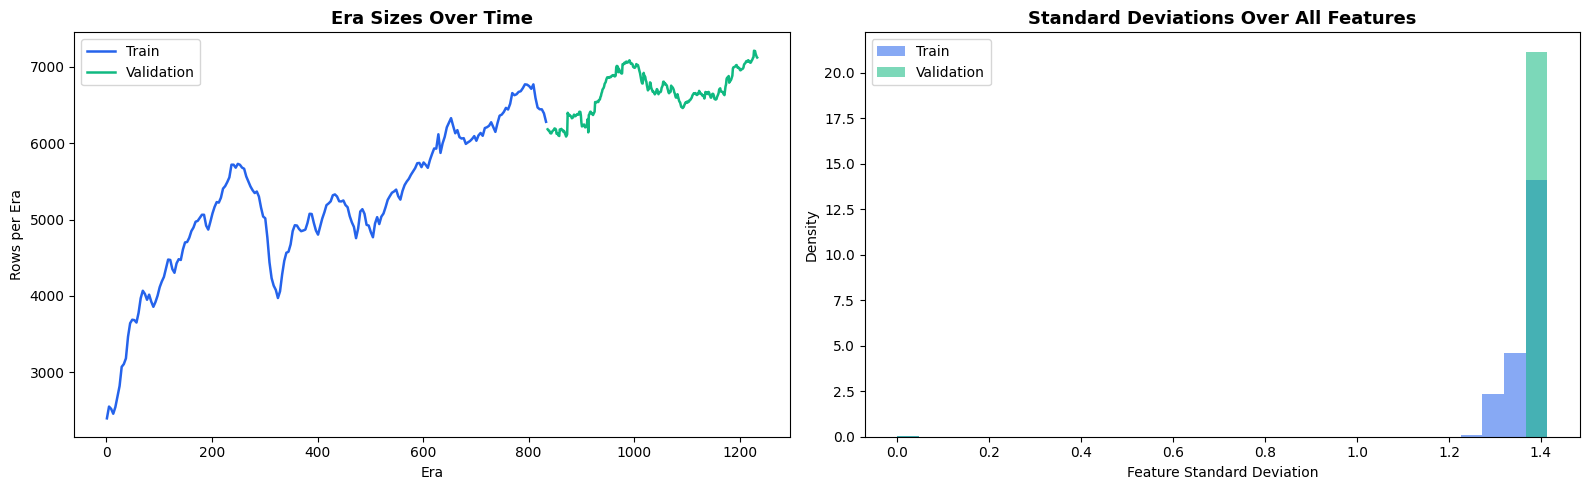

Top 10 Features according to absolute correlation with target:


feature_strength_32        0.011628
feature_constitution_30    0.011232
feature_constitution_29    0.009830
feature_charisma_148       0.009086
feature_wisdom_9           0.008691
feature_constitution_36    0.008650
feature_charisma_150       0.008487
feature_strength_57        0.008450
feature_charisma_40        0.008390
feature_constitution_28    0.008307
dtype: float64

ADF Stationarity Check on Top 10 Features (Per-Era Means):


,feature,adf_stat,adf_pvalue,stationary_at_5pct
0,feature_strength_32,-6.3000,0.0,True
1,feature_constitution_30,-6.3569,0.0,True
2,feature_constitution_29,-6.3569,0.0,True
3,feature_charisma_148,-6.3569,0.0,True
4,feature_wisdom_9,-6.3000,0.0,True
5,feature_constitution_36,-6.3000,0.0,True
6,feature_charisma_150,-6.3569,0.0,True
7,feature_strength_57,-6.3000,0.0,True
8,feature_charisma_40,-6.4167,0.0,True
9,feature_constitution_28,-6.3569,0.0,True


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

train_era_sizes = train_df.groupby(ERA_COL)[TARGET_COL].size()
val_era_sizes = validation_df.groupby(ERA_COL)[TARGET_COL].size()
axes[0].plot(train_era_sizes.index, train_era_sizes.to_numpy(), color='#2563eb', linewidth=1.8, label='Train')
axes[0].plot(val_era_sizes.index, val_era_sizes.to_numpy(), color='#10b981', linewidth=1.8, label='Validation')
axes[0].set_title('Era Sizes Over Time', weight='bold', fontsize=13)
axes[0].set_xlabel('Era')
axes[0].set_ylabel('Rows per Era')
axes[0].legend()

train_feat_stds = train_df[feature_columns].astype(np.float32).std()
val_feat_stds = validation_df[feature_columns].astype(np.float32).std()
axes[1].hist(train_feat_stds, bins=30, alpha=0.55, density=True, color='#2563eb', label='Train')
axes[1].hist(val_feat_stds, bins=30, alpha=0.55, density=True, color='#10b981', label='Validation')
axes[1].set_title('Standard Deviations Over All Features', weight='bold', fontsize=13)
axes[1].set_xlabel('Feature Standard Deviation')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()

corr_with_target = train_df[feature_columns].corrwith(train_df[TARGET_COL]).abs().sort_values(ascending=False)
print('Top 10 Features according to absolute correlation with target:')
display(corr_with_target.head(10))

eda_stationarity_df = compute_eda_era_stationarity(train_df, list(corr_with_target.head(10).index), era_col=ERA_COL)
print('ADF Stationarity Check on Top 10 Features (Per-Era Means):')
display(eda_stationarity_df)

In [6]:
input_columns = [ERA_COL] + ([TICKER_COL] if TICKER_COL in train_df.columns and TICKER_COL in validation_df.columns else []) + feature_columns
X_train = train_df[input_columns].reset_index(drop=True)
y_train = train_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
train_eras = train_df[ERA_COL].astype(np.int32).reset_index(drop=True)

X_validation = validation_df[input_columns].reset_index(drop=True)
y_validation = validation_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
validation_eras = validation_df[ERA_COL].astype(np.int32).reset_index(drop=True)

# Retain only lightweight validation metadata for diagnostics export and free raw DataFrames (~3.8 GB for feature_set='all')
val_diag_meta = validation_df[[c for c in ('id', 'numerai_ticker', 'date', ERA_COL) if c in validation_df.columns]].reset_index(drop=True).copy()
del train_df, validation_df
gc.collect()

# Strictly chronological walk-forward CV splitter (`TimeSeriesSplit` with dynamic `embargo_eras`)
unique_train_eras = np.array(sorted(train_eras.unique()))
if n_splits <= 1:
    split_index = int(len(unique_train_eras) * cv_split)
    era_splits = [(np.arange(0, max(1, split_index - embargo_eras)), np.arange(split_index, len(unique_train_eras)))]
else:
    effective_gap = min(int(embargo_eras), max(0, (len(unique_train_eras) // (n_splits + 1)) - 1))
    era_splits = TimeSeriesSplit(n_splits=n_splits, gap=effective_gap).split(unique_train_eras)
cv_object = [
    (
        np.flatnonzero(train_eras.isin(unique_train_eras[fold_train_eras]).to_numpy()),
        np.flatnonzero(train_eras.isin(unique_train_eras[fold_test_eras]).to_numpy()),
    )
    for fold_train_eras, fold_test_eras in era_splits
]

In [7]:
raw_feature_sets = feature_metadata.get('feature_sets', {})
meta_set_names = {'small', 'medium', 'all'}
active_feature_set_cols = set(feature_columns)
unity_feature_groups_dict = {
    group_name: tuple(col for col in group_cols if col in active_feature_set_cols)
    for group_name, group_cols in raw_feature_sets.items()
    if group_name not in meta_set_names and isinstance(group_cols, list)
}
unity_feature_groups_dict = {k: v for k, v in unity_feature_groups_dict.items() if len(v) >= 2}
unity_feature_groups = tuple(sorted(unity_feature_groups_dict.items())) if unity_feature_groups_dict else None

numerai_extractions = NumeraiExtractions(
    era_col=ERA_COL,
    target_col=TARGET_COL,
    ticker_col=TICKER_COL,
    year_horizon_filter=None,
    variance_threshold=None,
    correlation_method='pandas_mean',
    abs_corr=True,
    top_k=None,
    feature_selection_percentile=None,
    sparse_selector=None,
    sparse_alpha=0.01,
    pca_n_components=None,
    quantize_scope='era',
    quantize_strategy='zscore',
    sequence_top_n=4,
    feature_groups=unity_feature_groups,
    basic_group_stats=None,
    fourier_period_eras=52,
    fourier_order=None,
    rolling_era_windows=(4, 12),
    include_rolling_era=False,
    era_lag_scales=(1, 2, 4),
    include_lag_diff=False,
    ticker_features=None,
    ticker_windows=(4, 12),
    ticker_lag_steps=None,
    era_dispersion_features=None,
    missing_fill_value=2.0,
)

bin_snapping_estimator = BinSnappingEstimator(
    extractor=clone(numerai_extractions),
    top_k=20,
    n_bins=5,
    correlation_method='pandas_mean',
    abs_corr=True,
    smoothing=0.0,
    agg_mode='mean',
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
)

lag_reversal_estimator = LagReversalEstimator(
    extractor=clone(numerai_extractions),
    lag=1,
    acf_mode='feature_mean',
    acf_metric='acf',
    acf_detrend='linear',
    acf_threshold=0.0,
    sign_mode='hard',
    top_k=None,
    correlation_method='pandas_mean',
    abs_corr=True,
    center_features=True,
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
)

persistence_estimator = PersistenceEstimator(
    extractor=None,
    ticker_col=TICKER_COL,
    persistence_mode='last',
    persistence_lag=target_horizon_eras,
    smoothing=0.0,
    top_k=None,
    correlation_method=None,
    abs_corr=True,
    era_weighting=era_weighting,
    recency_decay=recency_decay,
    prediction_transform=None,
    bias_correction=None,
    walk_forward_step_eras=None,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=1,
    era_col=ERA_COL,
    target_col=TARGET_COL,
    verbose=verbose,
    random_state=random_state,
)

bin_snapping_pipeline = Pipeline([('estimator', bin_snapping_estimator)])
lag_reversal_pipeline = Pipeline([('estimator', lag_reversal_estimator)])
persistence_pipeline = Pipeline([('estimator', persistence_estimator)])
print('Baseline A pipeline ready:', bin_snapping_pipeline)
print('Baseline E pipeline ready:', lag_reversal_pipeline)
print('Persistence pipeline ready:', persistence_pipeline)

Baseline A pipeline ready: Pipeline(steps=[('estimator',
                 BinSnappingEstimator(extractor=NumeraiExtractions(),
                                      target_horizon_eras=12, verbose=3))])
Baseline E pipeline ready: Pipeline(steps=[('estimator',
                 LagReversalEstimator(extractor=NumeraiExtractions(),
                                      target_horizon_eras=12, verbose=3))])
Persistence pipeline ready: Pipeline(steps=[('estimator',
                 PersistenceEstimator(persistence_lag=12,
                                      target_horizon_eras=12, verbose=3))])


# Params

## Grid

In [8]:
# SHARED `NumeraiExtractions` GRID SPACE (Used by both `BinSnappingEstimator` and `LagReversalEstimator`)
GRID_EXTRACTOR_PARAM_SPACE = {
    # ----------------------------------------------------------
    # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
    # ----------------------------------------------------------
    'estimator__extractor__era_col': [ERA_COL],
    'estimator__extractor__ticker_col': [TICKER_COL],
    'estimator__extractor__target_col': [
        TARGET_COL,
        # 'target_cyrusd_20',
        # 'target_teager2b_20',
    ],
    'estimator__extractor__year_horizon_filter': [
        None,
        # (1, 2, 3),
        # (4, 5, 6),
        # (7, 8, 9),
    ],
    'estimator__extractor__variance_threshold': [
        None,
        # 0.02,
        # 0.05,
        # 0.10,
    ],
    'estimator__extractor__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman'
    ],
    'estimator__extractor__abs_corr': [
        True,
        # False,
    ],
    'estimator__extractor__top_k': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__extractor__feature_selection_percentile': [
        None,
        # 25.0,
        # 50.0,
        # 75.0,
        # 100.0,
    ],
    'estimator__extractor__sparse_selector': [
        None,
        # 'lasso',
        # 'elasticnet',
    ],
    'estimator__extractor__sparse_alpha': [
        0.01,
        # 0.001,
        # 0.1,
    ],
    'estimator__extractor__pca_n_components': [
        None,
        # 10,
        # 20,
        # 0.90,
    ],
    'estimator__extractor__quantize_scope': [
        'era',
        # 'train_fit',
        # 'global',
    ],
    'estimator__extractor__quantize_strategy': [
        'zscore',
        # 'quantile',
    ],
    'estimator__extractor__sequence_top_n': [
        4,
        # 2,
        # 8,
    ],
    'estimator__extractor__missing_fill_value': [
        2.0,
        # 0.0,
        # 4.0,
        # 'mean',
        # 'median',
        # 'era_mean',
        # 'era_median',
    ],

    # ----------------------------------------------------------
    # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
    # ----------------------------------------------------------
    'estimator__extractor__basic_group_stats': [
        None,
        # 'mean',
        # 'std',
        # 'skew',
        # 'mean|std',
        # 'mean|skew',
        # 'std|skew',
        # 'mean|std|skew',
    ],
    'estimator__extractor__fourier_period_eras': [
        52,
        # 26,
        # 13,
    ],
    'estimator__extractor__fourier_order': [
        None,
        # 1,
        # 2,
        # 3,
    ],
    'estimator__extractor__rolling_era_windows': [
        (4, 12),
        # (2, 6, 12),
        # (4, 8, 16),
    ],
    'estimator__extractor__include_rolling_era': [
        False,
        # True,
    ],
    'estimator__extractor__era_lag_scales': [
        (1, 2, 4),
        # (1, 2, 4, 8),
        # (2, 4, 8),
    ],
    'estimator__extractor__include_lag_diff': [
        False,
        # True,
    ],
    'estimator__extractor__ticker_features': [
        None,
        # 'rolling_mean',
        # 'momentum_diff',
        # 'weeks_since_high',
        # 'rolling_rank',
        # 'weeks_since_change',
        # 'expanding_stats',
        # 'raw_lags',
        # 'rolling_mean|momentum_diff',
        # 'rolling_mean|momentum_diff|rolling_rank',
        # 'expanding_stats|raw_lags',
        # 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
    ],
    'estimator__extractor__ticker_windows': [
        (4, 12),
        # (2, 6, 12),
    ],
    'estimator__extractor__ticker_lag_steps': [
        None,
        # (1, 2),
        # (1, 2, 4),
    ],
    'estimator__extractor__era_dispersion_features': [
        None,
        # 'mean',
        # 'std',
        # 'extreme_frac',
        # 'mean|std',
        # 'mean|extreme_frac',
        # 'std|extreme_frac',
        # 'mean|std|extreme_frac',
    ],
}

GRID_PARAM_SPACE_BIN_SNAPPING = {
    **GRID_EXTRACTOR_PARAM_SPACE,

    # ----------------------------------------------------------
    # MODEL — Baseline A (`BinSnappingEstimator` — Map Matching Lookup Table)
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__top_k': [
        20,
        # None,
        # 10,
        # 40,
    ],
    'estimator__n_bins': [
        5,
        # 3,
        # 7,
    ],
    'estimator__abs_corr': [
        True,
        # False,
    ],
    'estimator__smoothing': [
        0.0,
        # 25.0,
        # 50.0,
        # 100.0,
    ],
    'estimator__agg_mode': [
        'mean',
        # 'corr_weighted',
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],
}

GRID_PARAM_SPACE_LAG_REVERSAL = {
    **GRID_EXTRACTOR_PARAM_SPACE,

    # ----------------------------------------------------------
    # MODEL — Baseline E (`LagReversalEstimator` — Era Autocorrelation / PACF Sign & Shrinkage Rule)
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__lag': [
        1,
        # 2,
        # 4,
        # 6,
    ],
    'estimator__acf_mode': [
        'feature_mean',
        # 'feature_corr',
    ],
    'estimator__acf_metric': [
        'acf',
        # 'pacf',
    ],
    'estimator__acf_detrend': [
        'linear',
        # None,
        # 'constant',
    ],
    'estimator__acf_threshold': [
        0.0,
        # -0.05,
        # 0.05,
    ],
    'estimator__sign_mode': [
        'hard',
        # 'soft_threshold',
        # 'tanh',
    ],
    'estimator__top_k': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__abs_corr': [
        True,
        # False,
    ],
    'estimator__center_features': [
        True,
        # False,
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],
}

# Decoupled Persistence Grid Space (Does NOT inherit `GRID_EXTRACTOR_PARAM_SPACE`)
GRID_PARAM_SPACE_PERSISTENCE = {
    # ----------------------------------------------------------
    # MODEL — Baseline P (`PersistenceEstimator` — Brownlee Target Persistence / Zero-Rule)
    # ----------------------------------------------------------
    'estimator__era_col': [ERA_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__ticker_col': [TICKER_COL],
    'estimator__persistence_mode': [
        'last',
        # 'expanding_mean',
        # None,
    ],
    'estimator__persistence_lag': [target_horizon_eras],
    'estimator__smoothing': [
        0.0,
        # 10.0,
        # 25.0,
        # 50.0,
    ],
    'estimator__prediction_transform': [
        None,
        # 'era_zscore',
        # 'era_rank',
    ],
    'estimator__bias_correction': [
        None,
        # 'mean_residual',
    ],
    'estimator__walk_forward_step_eras': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__walk_forward_window': [
        walk_forward_window,
        # 'expanding',
        # 'sliding',
    ],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [
        1,
        # 2,
        # 4,
        # 12,
    ],
    'estimator__era_weighting': [
        era_weighting,
        # None,
        # 'equal_era',
        # 'recency_linear',
        # 'recency_exp',
    ],
    'estimator__recency_decay': [
        recency_decay,
        # 0.001,
        # 0.010,
    ],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],
}

## Bayesian

In [9]:
# BAYESIAN SEARCH ONLY
# Shared `BAYESIAN_EXTRACTOR_PARAM_SPACE` is used by both `BinSnappingEstimator` and `LagReversalEstimator`.
# Mode/selection parameters start with `None` (off); boolean `include_*` flags use `[False, True]`.
BAYESIAN_EXTRACTOR_PARAM_SPACE = dict()
BAYESIAN_PARAM_SPACE_BIN_SNAPPING = dict()
BAYESIAN_PARAM_SPACE_LAG_REVERSAL = dict()
BAYESIAN_PARAM_SPACE_PERSISTENCE = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_EXTRACTOR_PARAM_SPACE = {
        # ----------------------------------------------------------
        # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
        # ----------------------------------------------------------
        'estimator__extractor__era_col': Categorical([ERA_COL]),
        'estimator__extractor__ticker_col': Categorical([TICKER_COL]),
        'estimator__extractor__target_col': Categorical([
            TARGET_COL,
        ]),
        'estimator__extractor__year_horizon_filter': Categorical([
            None,
            (1, 2, 3),
            (4, 5, 6),
            (7, 8, 9),
        ]),
        'estimator__extractor__variance_threshold': Categorical([
            None,
            0.02,
            0.05,
            0.10,
        ]),
        'estimator__extractor__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__extractor__abs_corr': Categorical([True, False]),
        'estimator__extractor__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__feature_selection_percentile': Categorical([
            None,
            25.0,
            50.0,
            75.0,
            100.0,
        ]),
        'estimator__extractor__sparse_selector': Categorical([
            None,
            'lasso',
            'elasticnet',
        ]),
        'estimator__extractor__sparse_alpha': Real(1e-4, 1e-1, prior='log-uniform'),
        'estimator__extractor__pca_n_components': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__quantize_scope': Categorical([
            'era',
            'train_fit',
            'global',
        ]),
        'estimator__extractor__quantize_strategy': Categorical([
            'zscore',
            'quantile',
        ]),
        'estimator__extractor__sequence_top_n': Categorical([
            2,
            4,
            8,
        ]),
        'estimator__extractor__missing_fill_value': Categorical([
            2.0,
            0.0,
            4.0,
            'mean',
            'median',
            'era_mean',
            'era_median',
        ]),

        # ----------------------------------------------------------
        # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
        # ----------------------------------------------------------
        'estimator__extractor__basic_group_stats': Categorical([
            None,
            'mean',
            'std',
            'skew',
            'mean|std',
            'mean|skew',
            'std|skew',
            'mean|std|skew',
        ]),
        'estimator__extractor__fourier_period_eras': Categorical([
            52,
            26,
            13,
        ]),
        'estimator__extractor__fourier_order': Categorical([
            None,
            1,
            2,
            3,
        ]),
        'estimator__extractor__rolling_era_windows': Categorical([
            (4, 12),
            (2, 6, 12),
            (4, 8, 16),
        ]),
        'estimator__extractor__include_rolling_era': Categorical([False, True]),
        'estimator__extractor__era_lag_scales': Categorical([
            (1, 2, 4),
            (1, 2, 4, 8),
            (2, 4, 8),
        ]),
        'estimator__extractor__include_lag_diff': Categorical([False, True]),
        'estimator__extractor__ticker_features': Categorical([
            None,
            'rolling_mean',
            'momentum_diff',
            'weeks_since_high',
            'rolling_rank',
            'weeks_since_change',
            'expanding_stats',
            'raw_lags',
            'rolling_mean|momentum_diff',
            'rolling_mean|momentum_diff|rolling_rank',
            'expanding_stats|raw_lags',
            'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
        ]),
        'estimator__extractor__ticker_windows': Categorical([
            (4, 12),
            (2, 6, 12),
        ]),
        'estimator__extractor__ticker_lag_steps': Categorical([
            None,
            (1, 2),
            (1, 2, 4),
        ]),
        'estimator__extractor__era_dispersion_features': Categorical([
            None,
            'mean',
            'std',
            'extreme_frac',
            'mean|std',
            'mean|extreme_frac',
            'std|extreme_frac',
            'mean|std|extreme_frac',
        ]),
    }

    BAYESIAN_PARAM_SPACE_BIN_SNAPPING = {
        **BAYESIAN_EXTRACTOR_PARAM_SPACE,

        # ----------------------------------------------------------
        # MODEL — Baseline A (`BinSnappingEstimator` — Map Matching Lookup Table)
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__n_bins': Categorical([
            5,
            3,
            7,
        ]),
        'estimator__abs_corr': Categorical([True, False]),
        'estimator__smoothing': Real(0.0, 100.0),
        'estimator__agg_mode': Categorical(['mean', 'corr_weighted']),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([
            1,
            2,
            4,
            5,
            10
        ]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),
    }
    BAYESIAN_PARAM_SPACE_BIN_SNAPPING = build_conditional_bayesian_spaces(
        drop_constant_dims(BAYESIAN_PARAM_SPACE_BIN_SNAPPING, bin_snapping_pipeline),
        total_n_iter=n_iter,
    )

    BAYESIAN_PARAM_SPACE_LAG_REVERSAL = {
        **BAYESIAN_EXTRACTOR_PARAM_SPACE,

        # ----------------------------------------------------------
        # MODEL — Baseline E (`LagReversalEstimator` — Era Autocorrelation / PACF Sign & Shrinkage Rule)
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__lag': Integer(1, 6),
        'estimator__acf_mode': Categorical(['feature_mean', 'feature_corr']),
        'estimator__acf_metric': Categorical(['acf', 'pacf']),
        'estimator__acf_detrend': Categorical([
            None,
            'linear',
            'constant',
        ]),
        'estimator__acf_threshold': Real(-0.20, 0.20),
        'estimator__sign_mode': Categorical([
            'hard',
            'soft_threshold',
            'tanh',
        ]),
        'estimator__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__abs_corr': Categorical([True, False]),
        'estimator__center_features': Categorical([True, False]),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([
            1,
            2,
            4,
            5,
            10
        ]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),
    }
    BAYESIAN_PARAM_SPACE_LAG_REVERSAL = build_conditional_bayesian_spaces(
        drop_constant_dims(BAYESIAN_PARAM_SPACE_LAG_REVERSAL, lag_reversal_pipeline),
        total_n_iter=n_iter,
    )

    # Decoupled Persistence Bayesian Space (Does NOT inherit `BAYESIAN_EXTRACTOR_PARAM_SPACE`)
    BAYESIAN_PARAM_SPACE_PERSISTENCE = {
        # ----------------------------------------------------------
        # MODEL — Baseline P (`PersistenceEstimator` — Brownlee Target Persistence / Zero-Rule)
        # ----------------------------------------------------------
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__ticker_col': Categorical([TICKER_COL]),
        'estimator__persistence_mode': Categorical([
            None,
            'last',
            'expanding_mean',
        ]),
        'estimator__persistence_lag': Categorical([target_horizon_eras]),
        'estimator__smoothing': Real(0.0, 100.0),
        'estimator__prediction_transform': Categorical([
            None,
            'era_zscore',
            'era_rank',
        ]),
        'estimator__bias_correction': Categorical([
            None,
            'mean_residual',
        ]),
        'estimator__walk_forward_step_eras': Categorical([
            None,
            20,
            40,
        ]),
        'estimator__walk_forward_window': Categorical([
            'expanding',
            'sliding',
        ]),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([
            1,
            2,
            4,
            12,
        ]),
        'estimator__era_weighting': Categorical([
            None,
            'equal_era',
            'recency_linear',
            'recency_exp',
        ]),
        'estimator__recency_decay': Real(0.001, 0.020),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),
    }
    BAYESIAN_PARAM_SPACE_PERSISTENCE = build_conditional_bayesian_spaces(
        drop_constant_dims(BAYESIAN_PARAM_SPACE_PERSISTENCE, persistence_pipeline),
        total_n_iter=n_iter,
    )

bin_snapping_param_names = set(bin_snapping_pipeline.get_params(deep=True))
lag_reversal_param_names = set(lag_reversal_pipeline.get_params(deep=True))
persistence_param_names = set(persistence_pipeline.get_params(deep=True))
assert set(GRID_PARAM_SPACE_BIN_SNAPPING).issubset(bin_snapping_param_names)
assert set(GRID_PARAM_SPACE_LAG_REVERSAL).issubset(lag_reversal_param_names)
assert set(GRID_PARAM_SPACE_PERSISTENCE).issubset(persistence_param_names)
for _bspace, _pnames in (
    (BAYESIAN_PARAM_SPACE_BIN_SNAPPING, bin_snapping_param_names),
    (BAYESIAN_PARAM_SPACE_LAG_REVERSAL, lag_reversal_param_names),
    (BAYESIAN_PARAM_SPACE_PERSISTENCE, persistence_param_names),
):
    _bkeys = set().union(*(sub.keys() for sub, _ in _bspace)) if isinstance(_bspace, list) else set(_bspace)
    assert _bkeys.issubset(_pnames)

if search_mode == 'bayes':
    bin_snapping_param_space = BAYESIAN_PARAM_SPACE_BIN_SNAPPING
    lag_reversal_param_space = BAYESIAN_PARAM_SPACE_LAG_REVERSAL
    persistence_param_space = BAYESIAN_PARAM_SPACE_PERSISTENCE
else:
    bin_snapping_param_space = GRID_PARAM_SPACE_BIN_SNAPPING
    lag_reversal_param_space = GRID_PARAM_SPACE_LAG_REVERSAL
    persistence_param_space = GRID_PARAM_SPACE_PERSISTENCE
print(f'Active search_mode={search_mode} | baseline_mode={baseline_mode}')

Active search_mode=bayes | baseline_mode=all


# Train

In [10]:
_train_t0 = time.perf_counter()
baseline_results = {}
search_summary_rows = []
cv_results_by_baseline = {}
fitted_default_models = {}

error_bin_cfg = {
    'mode': error_bin_mode,
    'pct_bins': error_pct_bins,
    'zero_tols': error_zero_tols,
    'abs_bins': error_abs_bins,
}

persistence_jobs = []
if baseline_mode in ('persistence', 'all'):
    persistence_jobs.append(('Baseline P (Persistence)', persistence_pipeline, persistence_param_space))

heavy_jobs = []
if baseline_mode in ('baseline_a', 'both', 'all'):
    heavy_jobs.append(('Baseline A (Bin-Snapping)', bin_snapping_pipeline, bin_snapping_param_space))
if baseline_mode in ('baseline_e', 'both', 'all'):
    heavy_jobs.append(('Baseline E (Lag-Reversal)', lag_reversal_pipeline, lag_reversal_param_space))

_cpu_count = os.cpu_count() or 1
_job_budget = _cpu_count if int(n_jobs) == -1 else max(1, int(n_jobs))
outer_jobs = min(_job_budget, len(heavy_jobs)) if heavy_jobs else 1

effective_cache_max_entries = (
    min(int(extraction_cache_max_entries), 2)
    if (outer_jobs > 1 and str(feature_set).strip().lower() in ('medium', 'all'))
    else int(extraction_cache_max_entries)
)
extraction_cache_cfg = {
    'enabled': extraction_cache_enabled,
    'max_entries': effective_cache_max_entries,
}

common_run_kwargs = dict(
    search_mode=search_mode,
    eval_mode=eval_mode,
    cv_object=cv_object,
    n_iter=n_iter,
    random_state=random_state,
    verbose=verbose,
    error_score=error_score,
    n_jobs=1,
    walk_forward_step_eras=walk_forward_step_eras,
    walk_forward_window=walk_forward_window,
    target_horizon_eras=target_horizon_eras,
    era_stride=era_stride,
    error_bin_config=error_bin_cfg,
    extraction_cache_config=extraction_cache_cfg,
)

# 1. Run Baseline P (Persistence) first in the main process on metadata-only columns (0 feature copies)
persistence_payloads = []
if persistence_jobs:
    persist_cols = [c for c in (ERA_COL, TICKER_COL) if c in X_train.columns]
    X_train_persist = X_train[persist_cols]
    X_val_persist = X_validation[persist_cols]
    print(f'Running Baseline P (Persistence) in main process on {persist_cols} (0 feature columns copied)')
    for b_name, b_pipe, b_space in persistence_jobs:
        persistence_payloads.append(
            run_baseline(
                b_name, b_pipe, b_space,
                X_train_persist, y_train, train_eras,
                X_val_persist, y_validation, validation_eras,
                [],
                **common_run_kwargs,
            )
        )
    del X_train_persist, X_val_persist

# 2. Run heavy feature baselines (A & E) in parallel via loky with memmap (max_nbytes='10M', at most 2 workers)
heavy_payloads = []
if heavy_jobs:
    print(
        f'Running {len(heavy_jobs)} heavy baseline(s) with outer_jobs={outer_jobs} '
        f'(n_jobs={n_jobs}, cpu_count={_cpu_count}, inner cv_n_jobs=1, extraction_cache_max_entries={effective_cache_max_entries})'
    )
    if outer_jobs > 1:
        heavy_payloads = Parallel(n_jobs=outer_jobs, backend='loky', max_nbytes='10M')(
            delayed(run_baseline)(
                b_name, b_pipe, b_space,
                X_train, y_train, train_eras,
                X_validation, y_validation, validation_eras,
                feature_columns,
                **common_run_kwargs,
            )
            for b_name, b_pipe, b_space in heavy_jobs
        )
    else:
        heavy_payloads = [
            run_baseline(
                b_name, b_pipe, b_space,
                X_train, y_train, train_eras,
                X_validation, y_validation, validation_eras,
                feature_columns,
                **common_run_kwargs,
            )
            for b_name, b_pipe, b_space in heavy_jobs
        ]

# Merge in original A -> E -> P order
payloads = list(heavy_payloads) + list(persistence_payloads)
for b_name, b_results, b_cv_df, b_summary_row, b_default_model in payloads:
    baseline_results.update(b_results)
    cv_results_by_baseline[b_name] = b_cv_df
    search_summary_rows.append(b_summary_row)
    fitted_default_models[b_name] = b_default_model

train_elapsed_s = time.perf_counter() - _train_t0
print(f'Completed {len(payloads)} baseline(s) in {train_elapsed_s:.1f}s (heavy outer_jobs={outer_jobs})')

Running Baseline P (Persistence) in main process on ['era', 'numerai_ticker'] (0 feature columns copied)
--- Baseline P (Persistence) — Final Training Scores ---
Percentage Summary | Numerai CORR: -0.76% | Positive Eras: 33.5% | Directional Accuracy: 29.8%
Numerai CORR: -0.0076
Spearman Correlation: -0.0101
Average Payout: -0.0504
Sharpe Ratio (Numerai / Spearman): -0.3956 / -0.5428
Mean Absolute Error (MAE): 0.2203
Forecast Bias (mean(y - y_hat)): -0.0011
Directional Hit Rate (vs 0.5): 0.2983 (29.8%)
Era CORR White-Noise & Regime Tests | Lag-1 ACF: 0.3735 | Ljung-Box p: 0.0000 | ARCH-LM p: 1.0000 | ADF p: 0.0000
Era CORR Tail Risk | Skew: 0.0086 | Excess Kurtosis: -0.1935 | Jarque-Bera p: 0.8129
[SANITY WARNING — WEAK/BROKEN SIGNAL] numerai_corr=-0.0076 < 0.005 floor (check alignment, target, or over-regularization).
--- Baseline P (Persistence) — Final Validation Scores ---
Percentage Summary | Numerai CORR: -0.20% | Positive Eras: 44.5% | Directional Accuracy: 31.4%
Numerai CORR: -0

In [11]:
comparison_columns = [
    'variant',
    'train_corr',
    'validation_corr',
    'validation_spearman',
    'validation_payout',
    'validation_sharpe',
    'validation_spearman_sharpe',
    'validation_mae',
    'forecast_bias',
    'directional_hit_rate',
    'era_corr_lag1_acf',
    'ljung_box_pvalue',
    'arch_lm_pvalue',
    'adf_pvalue',
    'era_corr_skew',
    'era_corr_kurtosis',
    'jarque_bera_pvalue',
    'feature_exposure',
    'max_drawdown',
    'final_stake',
    'net_profit',
    'total_return_pct',
    'max_drawdown_pct',
    'max_drawdown_gbp',
    'worst_era_gbp',
    'corr_gap',
    'sanity_status',
]
comparison_df = (
    pd.DataFrame([{column: result[column] for column in comparison_columns} for result in baseline_results.values()])
    .sort_values(['validation_sharpe', 'validation_corr'], ascending=False, kind='stable')
    .reset_index(drop=True)
)
search_summary_df = (
    pd.DataFrame(search_summary_rows)
    .sort_values('best_cv_corr', ascending=False, kind='stable')
    .reset_index(drop=True)
)
best_variant_name = str(comparison_df.loc[0, 'variant'])
best_validation_era_corrs = baseline_results[best_variant_name]['validation_era_corrs']
best_validation_corr = baseline_results[best_variant_name]['validation_corr']

print('Deterministic [Default] Validation Comparison (Official Numerai CORR + Tutorial Spearman/Payout/Sharpe/MAE/Feature Exposure):')
display(comparison_df)
print(f'CV Search Summary ({search_mode}, refit=False):')
display(search_summary_df)
print(f'Top Default Holdout Baseline: {best_variant_name}')

Deterministic [Default] Validation Comparison (Official Numerai CORR + Tutorial Spearman/Payout/Sharpe/MAE/Feature Exposure):


,variant,train_corr,validation_corr,validation_spearman,validation_payout,validation_sharpe,validation_spearman_sharpe,validation_mae,forecast_bias,directional_hit_rate,...,feature_exposure,max_drawdown,final_stake,net_profit,total_return_pct,max_drawdown_pct,max_drawdown_gbp,worst_era_gbp,corr_gap,sanity_status
0,Baseline A (Bin-Snapping) [Tuned Walk-Forward],0.0192,0.0062,0.0084,0.0418,0.4800,0.6114,0.9132,0.5000,0.5054,...,0.1295,0.2333,2126.78,1126.78,112.68,-43.36,-791.88,-409.88,0.0130,OK
1,Baseline E (Lag-Reversal) [Walk-Forward],0.0220,0.0061,0.0096,0.0481,0.4525,0.6973,0.5167,0.5000,0.5058,...,0.1887,0.4007,2213.88,1213.88,121.39,-57.75,-988.65,-333.96,0.0159,OK
2,Baseline A (Bin-Snapping) [Tuned],0.0192,0.0059,0.0076,0.0378,0.4499,0.5389,0.9132,0.5000,0.5044,...,0.1470,0.2742,1954.91,954.91,95.49,-41.52,-629.63,-279.19,0.0133,OK
3,Baseline P (Persistence) [Tuned Walk-Forward],0.0039,0.0068,0.0073,0.0363,0.4405,0.4823,0.9099,0.5000,0.5038,...,NaN,0.3844,2253.57,1253.57,125.36,-45.12,-1640.55,-572.67,-0.0029,OK
4,Baseline A (Bin-Snapping) [Walk-Forward],0.0206,0.0068,0.0088,0.0439,0.4309,0.5210,0.1503,0.0000,0.5054,...,0.1579,0.6618,2345.49,1345.49,134.55,-67.06,-865.34,-283.45,0.0138,OK
5,Baseline E (Lag-Reversal) [Default],0.0220,0.0056,0.0102,0.0511,0.4099,0.7340,0.5248,0.5000,0.5068,...,0.1987,0.4422,2036.42,1036.42,103.64,-60.68,-1032.24,-321.15,0.0164,OK
6,Baseline A (Bin-Snapping) [Default],0.0206,0.0062,0.0082,0.0408,0.3702,0.4888,0.1504,0.0000,0.5051,...,0.1648,0.9129,2245.66,1245.66,124.56,-72.31,-839.39,-344.07,0.0144,OK
7,Baseline P (Persistence) [Tuned],0.0039,0.0050,0.0065,0.0324,0.3333,0.4524,0.9043,0.5000,0.5047,...,NaN,0.6198,2023.54,1023.54,102.35,-55.56,-1483.26,-580.37,-0.0011,OK
8,Baseline E (Lag-Reversal) [Tuned],0.0190,0.0049,0.0063,0.0313,0.2859,0.3472,0.5042,0.5016,0.5039,...,0.1246,0.8009,2192.76,1192.76,119.28,-75.01,-1116.81,-317.96,0.0141,LOW_SIGNAL_WARNING
9,Baseline E (Lag-Reversal) [Tuned Walk-Forward],0.0190,0.0046,0.0062,0.0309,0.2696,0.3426,0.5024,0.5006,0.5037,...,0.1203,0.8156,2160.61,1160.61,116.06,-75.22,-1110.33,-301.01,0.0144,LOW_SIGNAL_WARNING


CV Search Summary (bayes, refit=False):


,baseline,search_mode,best_cv_corr,best_cv_corr_pct,best_params
0,Baseline A (Bin-Snapping),bayes,0.014251,1.43,"{'estimator__abs_corr': False, 'estimator__agg..."
1,Baseline P (Persistence),bayes,0.013346,1.33,"{'estimator__bias_correction': None, 'estimato..."
2,Baseline E (Lag-Reversal),bayes,0.013118,1.31,"{'estimator__abs_corr': False, 'estimator__acf..."


Top Default Holdout Baseline: Baseline A (Bin-Snapping) [Tuned Walk-Forward]


# Analysis

Exported Numerai Diagnostics predictions Parquet (MMC & FNC): /kaggle/working/results_numerai_v6.0_all_eras_stride4_baselines_ae_target_bayes/validation_predictions.parquet


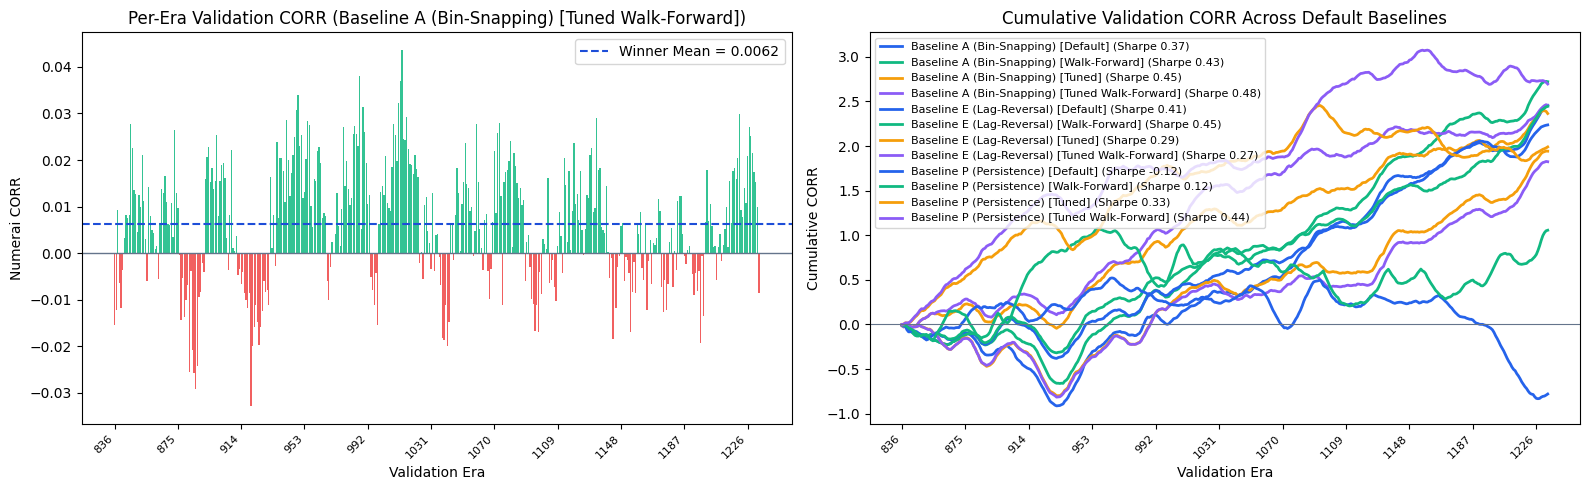

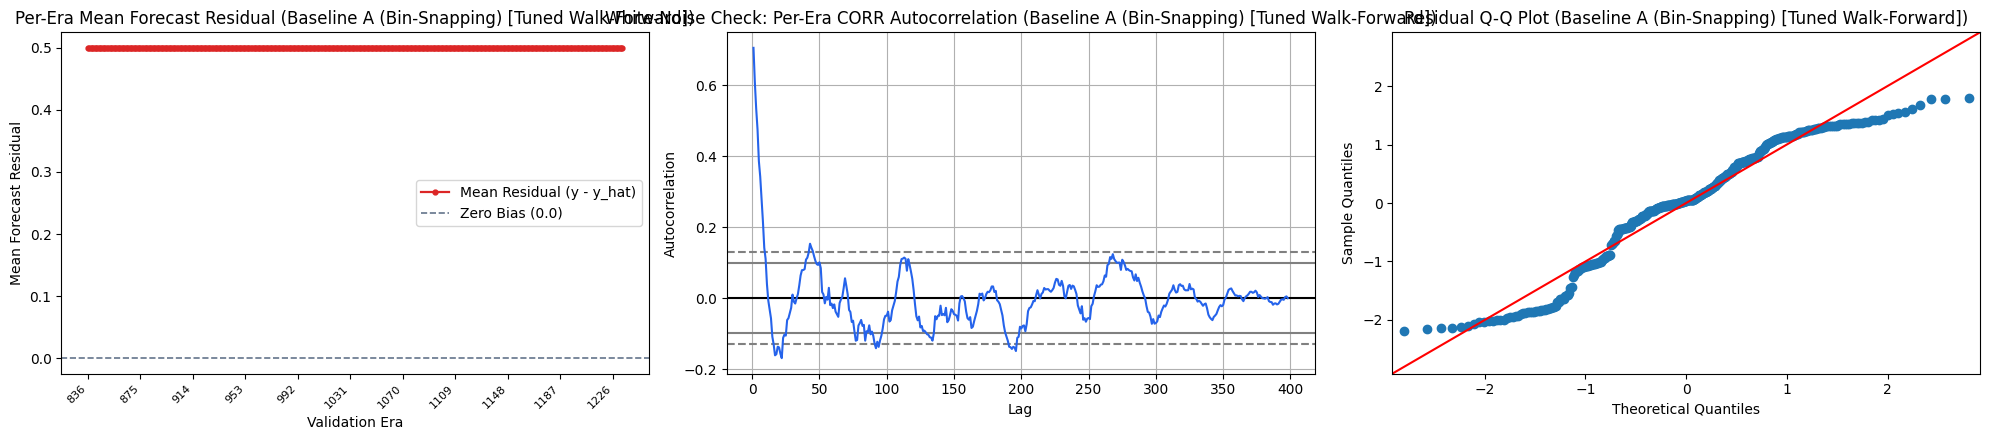

In [12]:
era_positions = np.arange(len(best_validation_era_corrs))
tick_step = max(1, len(best_validation_era_corrs) // 10)
tick_labels = best_validation_era_corrs.index.astype(str)[::tick_step]
line_colors = ['#2563eb', '#10b981', '#f59e0b', '#8b5cf6']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.bar(
    era_positions,
    best_validation_era_corrs.to_numpy(),
    color=['#10b981' if era_corr >= 0 else '#ef4444' for era_corr in best_validation_era_corrs.to_numpy()],
    alpha=0.85,
)
ax.axhline(0.0, color='#64748b', linewidth=1.0)
ax.axhline(best_validation_corr, color='#1d4ed8', linestyle='--', linewidth=1.5, label=f'Winner Mean = {best_validation_corr:.4f}')
ax.set_xticks(era_positions[::tick_step])
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_xlabel('Validation Era')
ax.set_ylabel('Numerai CORR')
ax.set_title(f'Per-Era Validation CORR ({best_variant_name})')
ax.legend()

ax = axes[1]
for color_index, (variant_name, result) in enumerate(baseline_results.items()):
    line_color = line_colors[color_index % len(line_colors)]
    ax.plot(
        era_positions,
        result['validation_era_corrs'].cumsum().to_numpy(),
        color=line_color,
        linewidth=2.0,
        label=f"{variant_name} (Sharpe {result['validation_sharpe']:.2f})",
    )
ax.axhline(0.0, color='#64748b', linewidth=0.8)
ax.set_xticks(era_positions[::tick_step])
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_xlabel('Validation Era')
ax.set_ylabel('Cumulative CORR')
ax.set_title('Cumulative Validation CORR Across Default Baselines')
ax.legend(fontsize=8)

plt.tight_layout()
if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(results_dir / f'{timestamp}_{experiment_name}_era_perf.png', dpi=140)
    comparison_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_comparison.csv', index=False)
if export_diagnostics or save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    diagnostics_parquet_path = export_diagnostics_predictions(
        val_diag_meta,
        baseline_results[best_variant_name]['validation_preds'],
        results_dir / 'validation_predictions.parquet',
        era_col=ERA_COL,
    )
    print('Exported Numerai Diagnostics predictions Parquet (MMC & FNC):', diagnostics_parquet_path)
plt.show()

# Brownlee Residual, White-Noise & Tail-Normality Diagnostics (Per-Era Mean Residual + Era CORR Autocorrelation + Residual Q-Q Plot)
winner_val_preds = np.asarray(baseline_results[best_variant_name]['validation_preds'], dtype=np.float64).ravel()
winner_residuals = pd.Series(y_validation.to_numpy(dtype=np.float64) - winner_val_preds, index=validation_eras.index)
per_era_mean_residuals = winner_residuals.groupby(validation_eras, sort=True).mean()

fig_res, axes_res = plt.subplots(1, 3, figsize=(20, 4.5))
axes_res[0].plot(era_positions, per_era_mean_residuals.to_numpy(), color='#dc2626', marker='o', markersize=3.5, linewidth=1.6, label='Mean Residual (y - y_hat)')
axes_res[0].axhline(0.0, color='#64748b', linestyle='--', linewidth=1.2, label='Zero Bias (0.0)')
axes_res[0].set_xticks(era_positions[::tick_step])
axes_res[0].set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
axes_res[0].set_xlabel('Validation Era')
axes_res[0].set_ylabel('Mean Forecast Residual')
axes_res[0].set_title(f'Per-Era Mean Forecast Residual ({best_variant_name})')
axes_res[0].legend()

if len(best_validation_era_corrs) >= 2:
    autocorrelation_plot(best_validation_era_corrs, ax=axes_res[1], color='#2563eb')
axes_res[1].set_title(f'White-Noise Check: Per-Era CORR Autocorrelation ({best_variant_name})')

if len(per_era_mean_residuals) >= 3:
    qqplot(per_era_mean_residuals.to_numpy(dtype=np.float64), line='45', fit=True, ax=axes_res[2])
axes_res[2].set_title(f'Residual Q-Q Plot ({best_variant_name})')
plt.tight_layout()
if save_results:
    plt.savefig(results_dir / f'{timestamp}_{experiment_name}_residual_white_noise.png', dpi=140)
plt.show()

Baseline A Learned Lookup Table (top 90 features):


,bin_0,bin_1,bin_2,bin_3,bin_4,train_corr
pca_comp_0,0.491915,0.496174,0.501330,0.502348,0.507575,1.0
pca_comp_1,0.500777,0.497624,0.498994,0.502192,0.504420,1.0
pca_comp_2,0.507281,0.502000,0.498391,0.498155,0.499679,1.0
pca_comp_3,0.492940,0.496776,0.499559,0.503009,0.509484,1.0
pca_comp_4,0.500754,0.500835,0.500766,0.499304,0.494006,1.0
pca_comp_5,0.502714,0.500260,0.498463,0.501874,0.497479,1.0
pca_comp_6,0.503652,0.500087,0.499641,0.500709,0.494905,1.0
pca_comp_7,0.497823,0.501388,0.500349,0.498362,0.500486,1.0
pca_comp_8,0.496454,0.499217,0.500118,0.500432,0.503330,1.0
pca_comp_9,0.494972,0.500045,0.499169,0.501290,0.503814,1.0


Baseline E Signal Rules | kept (+1)=47 | inverted (-1)=25


,feature,target_corr,lag_acf,sign_rule,effective_weight
0,pca_comp_1,0.019575,0.005017,0.998423,0.019544
1,row_feat_mean_bin,0.018103,0.375899,1.000000,0.018103
2,feature_strength_mean,0.014469,0.159237,0.999997,0.014469
3,feature_wisdom_mean,0.013030,-0.003554,0.997779,0.013001
4,feature_charisma_mean,0.012074,0.095149,0.999957,0.012074
5,feature_constitution_mean,0.010788,0.025897,0.999316,0.010780
6,pca_comp_2,0.006427,0.383198,1.000000,0.006427
7,pca_comp_6,0.006390,-0.088040,0.936781,0.005986
8,pca_comp_3,0.005253,-0.375063,-0.999368,-0.005250
9,feature_constitution_267_ticker_wks_high2,0.004325,-0.110378,0.852256,0.003686


Baseline P (Persistence) | mode=expanding_mean | lag=12 | global_mean=0.5000 | tracked_tickers=13899


,ticker,persisted_target,obs_count,last_era
0,000270 KR,0.499992,105,833
1,000810 KR,0.521936,105,833
2,003490 KR,0.478048,105,833
3,004170 KR,0.490018,105,833
4,005380 KR,0.519941,105,833
5,005490 KR,0.492013,105,833
6,005930 KR,0.539890,105,833
7,005940 KR,0.496002,105,833
8,006360 KR,0.484033,105,833
9,006400 KR,0.533905,105,833


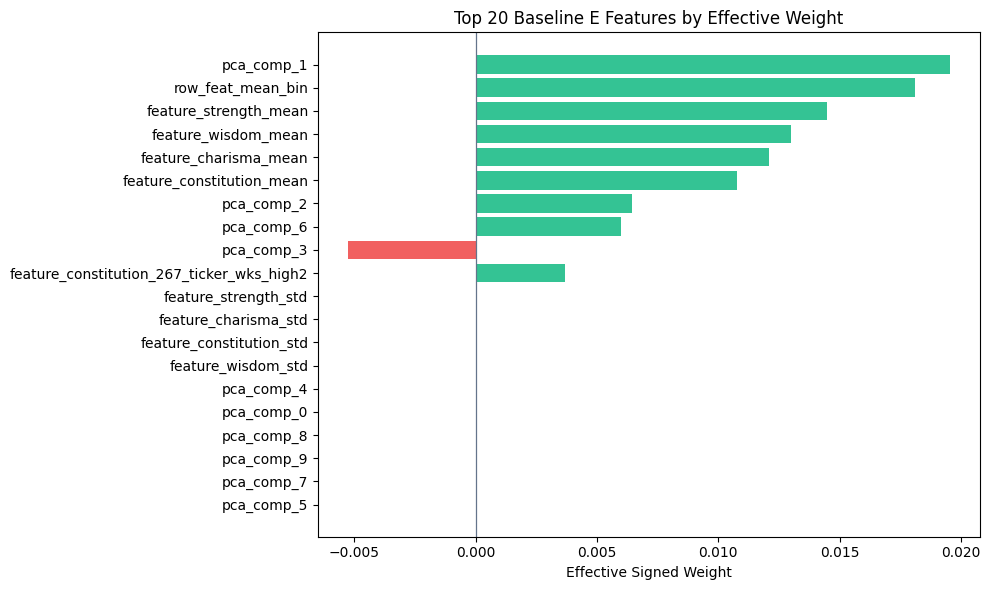

In [13]:
if 'Baseline A (Bin-Snapping)' in fitted_default_models:
    fitted_bin_snapping = fitted_default_models['Baseline A (Bin-Snapping)'].named_steps['estimator']
    lookup_table_df = pd.DataFrame(fitted_bin_snapping.lookup_table_).T
    lookup_table_df.columns = [f'bin_{bin_index}' for bin_index in lookup_table_df.columns]
    lookup_table_df['train_corr'] = fitted_bin_snapping.selected_corrs_
    print(f'Baseline A Learned Lookup Table (top {len(lookup_table_df)} features):')
    display(lookup_table_df.head(15))

if 'Baseline E (Lag-Reversal)' in fitted_default_models:
    fitted_lag_reversal = fitted_default_models['Baseline E (Lag-Reversal)'].named_steps['estimator']
    n_kept_signals = int((fitted_lag_reversal.inversion_signs_ > 0).sum())
    n_inverted_signals = int((fitted_lag_reversal.inversion_signs_ < 0).sum())
    print(f'Baseline E Signal Rules | kept (+1)={n_kept_signals} | inverted (-1)={n_inverted_signals}')
    display(fitted_lag_reversal.rule_summary_.head(20))

if 'Baseline P (Persistence)' in fitted_default_models:
    fitted_persistence = fitted_default_models['Baseline P (Persistence)'].named_steps['estimator']
    print(
        f'Baseline P (Persistence) | mode={fitted_persistence.persistence_mode} | '
        f'lag={fitted_persistence.persistence_lag} | global_mean={fitted_persistence.global_mean_:.4f} | '
        f'tracked_tickers={len(fitted_persistence.ticker_lookup_)}'
    )
    display(fitted_persistence.persistence_table_.head(15))

if plt is not None:
    if 'Baseline E (Lag-Reversal)' in fitted_default_models:
        top_rule_df = fitted_lag_reversal.rule_summary_.head(20).copy()
        top_rule_df['abs_weight'] = top_rule_df['effective_weight'].abs()
        plot_rule_df = top_rule_df.sort_values('abs_weight', ascending=True)
        fig_imp, ax_imp = plt.subplots(figsize=(10, 6))
        bar_colors = ['#10b981' if w >= 0 else '#ef4444' for w in plot_rule_df['effective_weight']]
        ax_imp.barh(plot_rule_df['feature'], plot_rule_df['effective_weight'], color=bar_colors, alpha=0.85)
        ax_imp.axvline(0.0, color='#64748b', linewidth=0.9)
        ax_imp.set_xlabel('Effective Signed Weight')
        ax_imp.set_title('Top 20 Baseline E Features by Effective Weight')
        plt.tight_layout()
        if save_results:
            results_dir.mkdir(parents=True, exist_ok=True)
            plt.savefig(results_dir / f'{timestamp}_{experiment_name}_baseline_e_weights.png', dpi=140)
        plt.show()
    elif 'Baseline A (Bin-Snapping)' in fitted_default_models:
        top_bin_df = lookup_table_df.head(20).copy()
        top_bin_df['abs_corr'] = top_bin_df['train_corr'].abs()
        plot_bin_df = top_bin_df.sort_values('abs_corr', ascending=True)
        fig_imp, ax_imp = plt.subplots(figsize=(10, 6))
        bar_colors = ['#2563eb' if c >= 0 else '#ef4444' for c in plot_bin_df['train_corr']]
        ax_imp.barh(plot_bin_df.index, plot_bin_df['train_corr'], color=bar_colors, alpha=0.85)
        ax_imp.axvline(0.0, color='#64748b', linewidth=0.9)
        ax_imp.set_xlabel('Training Target Correlation')
        ax_imp.set_title('Top 20 Baseline A Features by Training Correlation')
        plt.tight_layout()
        if save_results:
            results_dir.mkdir(parents=True, exist_ok=True)
            plt.savefig(results_dir / f'{timestamp}_{experiment_name}_baseline_a_corrs.png', dpi=140)
        plt.show()

In [14]:
for baseline_name, cv_results_df in cv_results_by_baseline.items():
    print(f'Top CV candidates for {baseline_name}:')
    display(cv_results_df.head(10))
    if save_results:
        results_dir.mkdir(parents=True, exist_ok=True)
        baseline_slug = 'baseline_a' if 'Baseline A' in baseline_name else ('baseline_e' if 'Baseline E' in baseline_name else 'persistence')
        cv_results_path = results_dir / f'{timestamp}_{experiment_name}_{baseline_slug}_{search_mode}_cv.csv'
        cv_results_df.to_csv(cv_results_path, index=False)
        print('Saved CV results CSV:', cv_results_path)

Top CV candidates for Baseline A (Bin-Snapping):


,candidate_id,mean_fit_time,std_fit_time,mean_score_time,std_score_time,split0_test_score,mean_test_score,std_test_score,rank_test_score,mean_test_corr_pct,...,extractor__top_k,extractor__variance_threshold,extractor__year_horizon_filter,n_bins,prediction_transform,recency_decay,smoothing,top_k,walk_forward_step_eras,walk_forward_window
0,4,28.669216,0.0,75.748823,0.0,0.014251,0.014251,0.0,1,1.43,...,40.0,NaN,None,5,era_zscore,0.006482,81.750309,NaN,40.0,expanding
1,28,22.464168,0.0,9.843513,0.0,0.013757,0.013757,0.0,2,1.38,...,NaN,0.05,"[1, 2, 3]",3,era_rank,0.002442,9.608621,40.0,NaN,expanding
2,7,50.288931,0.0,243.115316,0.0,0.013547,0.013547,0.0,3,1.35,...,NaN,0.05,"[1, 2, 3]",3,era_zscore,0.012329,76.697552,20.0,10.0,expanding
3,36,58.252733,0.0,32.321193,0.0,0.013160,0.013160,0.0,4,1.32,...,10.0,0.02,"[1, 2, 3]",5,era_rank,0.006172,25.899058,10.0,NaN,sliding
4,33,9.435269,0.0,20.639934,0.0,0.012417,0.012417,0.0,5,1.24,...,NaN,0.02,"[4, 5, 6]",5,None,0.004800,3.002744,10.0,40.0,sliding
5,22,18.015402,0.0,45.303441,0.0,0.011550,0.011550,0.0,6,1.16,...,NaN,0.05,"[1, 2, 3]",7,era_zscore,0.016092,26.056959,NaN,40.0,expanding
6,2,20.110523,0.0,11.375819,0.0,0.010368,0.010368,0.0,7,1.04,...,20.0,0.10,"[7, 8, 9]",7,era_zscore,0.016014,85.768565,40.0,NaN,sliding
7,11,66.434976,0.0,193.437825,0.0,0.010334,0.010334,0.0,8,1.03,...,20.0,0.02,"[1, 2, 3]",7,era_zscore,0.017732,98.685279,NaN,40.0,sliding
8,34,18.721708,0.0,48.375777,0.0,0.010223,0.010223,0.0,9,1.02,...,40.0,0.10,"[7, 8, 9]",5,None,0.012163,72.657087,40.0,20.0,expanding
9,21,57.345207,0.0,206.105806,0.0,0.009700,0.009700,0.0,10,0.97,...,NaN,0.10,"[4, 5, 6]",7,None,0.003202,74.568697,20.0,20.0,expanding


Saved CV results CSV: /kaggle/working/results_numerai_v6.0_all_eras_stride4_baselines_ae_target_bayes/20261124_044330_numerai_v6.0_all_eras_stride4_baselines_ae_baseline_a_bayes_cv.csv
Top CV candidates for Baseline E (Lag-Reversal):


,candidate_id,mean_fit_time,std_fit_time,mean_score_time,std_score_time,split0_test_score,mean_test_score,std_test_score,rank_test_score,mean_test_corr_pct,...,extractor__top_k,extractor__variance_threshold,extractor__year_horizon_filter,lag,prediction_transform,recency_decay,sign_mode,top_k,walk_forward_step_eras,walk_forward_window
0,19,49.343983,0.0,39.682161,0.0,0.013118,0.013118,0.0,1,1.31,...,10.0,NaN,"[4, 5, 6]",5,None,0.008920,tanh,10.0,NaN,sliding
1,20,125.965905,0.0,102.061791,0.0,0.011103,0.011103,0.0,2,1.11,...,10.0,0.10,"[1, 2, 3]",2,None,0.014882,soft_threshold,NaN,NaN,expanding
2,26,3.397462,0.0,5.143640,0.0,0.010410,0.010410,0.0,3,1.04,...,20.0,0.02,"[7, 8, 9]",2,None,0.002949,hard,10.0,10.0,expanding
3,28,132.311497,0.0,509.002993,0.0,0.010314,0.010314,0.0,4,1.03,...,40.0,0.05,None,4,era_rank,0.008426,soft_threshold,40.0,20.0,expanding
4,1,11.222474,0.0,9.409700,0.0,0.009097,0.009097,0.0,5,0.91,...,10.0,0.02,"[1, 2, 3]",3,None,0.009703,soft_threshold,10.0,NaN,sliding
5,23,49.894934,0.0,32.464894,0.0,0.008709,0.008709,0.0,6,0.87,...,10.0,0.05,"[4, 5, 6]",1,era_rank,0.009499,soft_threshold,10.0,NaN,expanding
6,25,32.746052,0.0,201.617570,0.0,0.008273,0.008273,0.0,7,0.83,...,NaN,NaN,None,1,era_zscore,0.005779,hard,NaN,10.0,sliding
7,7,42.689215,0.0,112.602612,0.0,0.008078,0.008078,0.0,8,0.81,...,40.0,0.10,"[1, 2, 3]",2,era_zscore,0.012340,hard,NaN,40.0,expanding
8,16,69.388771,0.0,38.364583,0.0,0.005636,0.005636,0.0,9,0.56,...,40.0,0.10,"[4, 5, 6]",6,era_rank,0.001347,soft_threshold,NaN,NaN,sliding
9,21,7.251642,0.0,13.569428,0.0,0.005132,0.005132,0.0,10,0.51,...,NaN,0.02,"[4, 5, 6]",2,None,0.008143,soft_threshold,10.0,20.0,expanding


Saved CV results CSV: /kaggle/working/results_numerai_v6.0_all_eras_stride4_baselines_ae_target_bayes/20261124_044330_numerai_v6.0_all_eras_stride4_baselines_ae_baseline_e_bayes_cv.csv
Top CV candidates for Baseline P (Persistence):


,candidate_id,mean_fit_time,std_fit_time,mean_score_time,std_score_time,split0_test_score,mean_test_score,std_test_score,rank_test_score,mean_test_corr_pct,...,worst_era_gbp,bias_correction,era_stride,era_weighting,persistence_mode,prediction_transform,recency_decay,smoothing,walk_forward_step_eras,walk_forward_window
0,32,0.704561,0.0,1.054567,0.0,0.013346,0.013346,0.0,1,1.33,...,-202.40,None,2,None,expanding_mean,era_zscore,0.002811,20.320157,NaN,sliding
1,24,0.717545,0.0,1.053188,0.0,0.013311,0.013311,0.0,2,1.33,...,-210.55,None,2,None,expanding_mean,None,0.012268,19.092300,NaN,sliding
2,16,1.093890,0.0,3.503446,0.0,0.011405,0.011405,0.0,3,1.14,...,-126.31,mean_residual,1,equal_era,expanding_mean,None,0.008180,25.761381,40.0,sliding
3,6,1.071531,0.0,3.628234,0.0,0.011043,0.011043,0.0,4,1.10,...,-163.13,mean_residual,1,None,expanding_mean,None,0.005217,67.851611,40.0,expanding
4,17,0.711502,0.0,2.269866,0.0,0.010991,0.010991,0.0,5,1.10,...,-378.82,None,2,recency_linear,expanding_mean,None,0.014891,22.575177,40.0,sliding
5,13,0.732341,0.0,2.320854,0.0,0.010811,0.010811,0.0,6,1.08,...,-265.78,mean_residual,2,recency_linear,expanding_mean,era_zscore,0.006891,56.536565,40.0,sliding
6,22,1.077991,0.0,4.769219,0.0,0.010799,0.010799,0.0,7,1.08,...,-64.57,None,1,equal_era,expanding_mean,None,0.012589,88.954854,20.0,sliding
7,36,1.146586,0.0,3.809524,0.0,0.010722,0.010722,0.0,8,1.07,...,-134.01,mean_residual,1,equal_era,expanding_mean,era_zscore,0.007199,24.181984,40.0,expanding
8,35,1.095797,0.0,4.765102,0.0,0.010684,0.010684,0.0,9,1.07,...,-84.45,None,1,equal_era,expanding_mean,None,0.016231,54.877048,20.0,sliding
9,31,1.079351,0.0,1.052405,0.0,0.010658,0.010658,0.0,10,1.07,...,-278.07,mean_residual,1,None,expanding_mean,None,0.014499,27.704701,NaN,expanding


Saved CV results CSV: /kaggle/working/results_numerai_v6.0_all_eras_stride4_baselines_ae_target_bayes/20261124_044330_numerai_v6.0_all_eras_stride4_baselines_ae_persistence_bayes_cv.csv


## Error-Direction Envelope Analysis (Per Baseline Model — Best Highlighted)

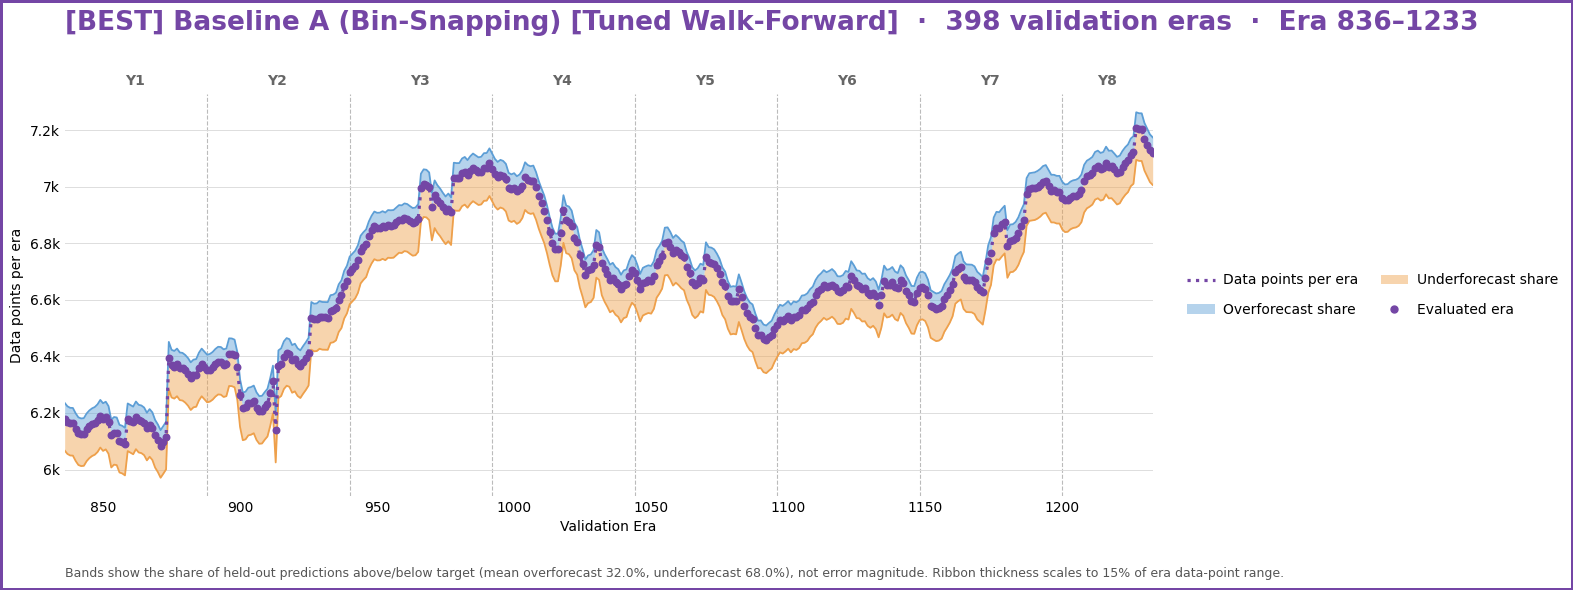

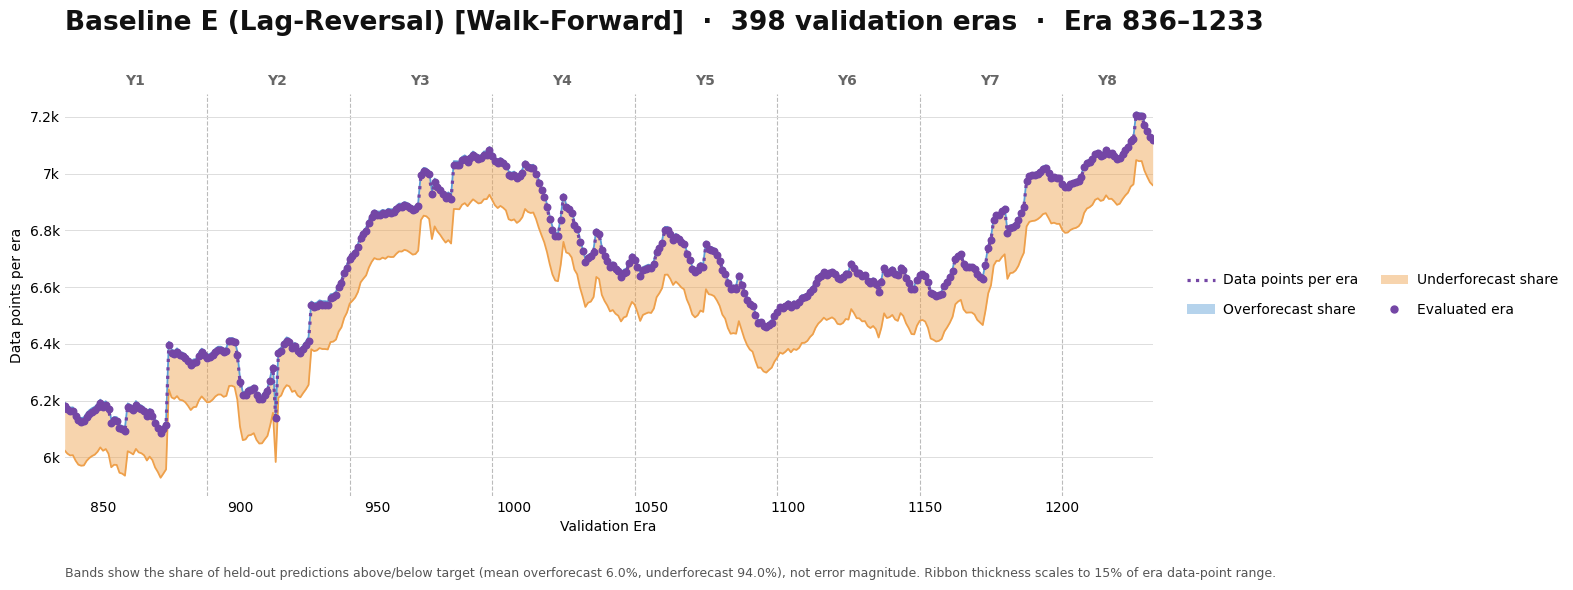

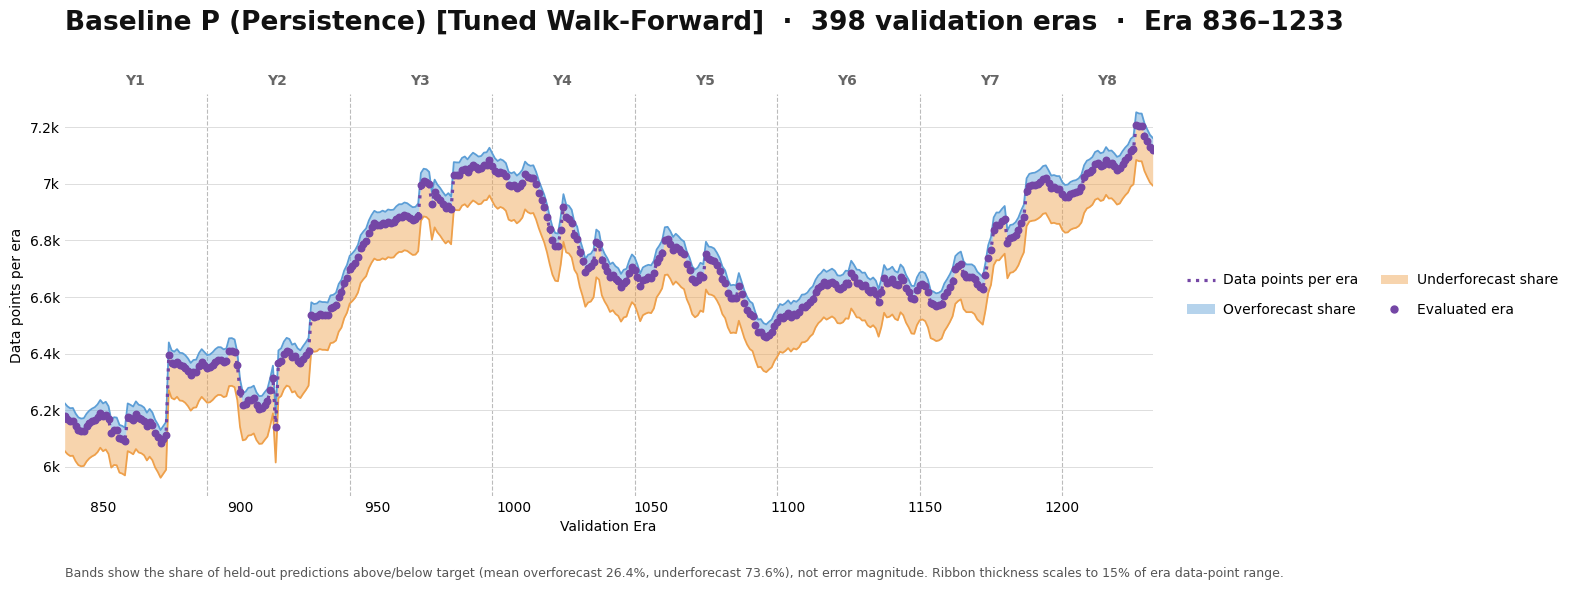

Best Model Envelope Summary (Baseline A (Bin-Snapping) [Tuned Walk-Forward]):


,data_points,under_share,over_share,mae,mean_residual,is_interpolated
era,,,,,,
836,6180,0.668770,0.331230,0.921550,-0.499960,False
837,6169,0.674988,0.325012,0.919890,-0.499959,False
838,6163,0.671751,0.328249,0.915326,-0.499959,False
839,6163,0.675158,0.324842,0.917983,-0.499959,False
840,6144,0.673503,0.326497,0.919680,-0.499959,False
841,6130,0.675367,0.324633,0.918181,-0.499959,False
842,6126,0.675155,0.324845,0.913678,-0.499959,False
843,6127,0.675045,0.324955,0.914908,-0.499959,False
844,6143,0.672961,0.327039,0.912025,-0.499959,False


In [15]:
envelope_dfs = {}
seen_model_families = set()
envelope_variants = []
for variant_name in comparison_df['variant'].tolist():
    model_family = variant_name.split(' [')[0]
    if model_family not in seen_model_families:
        seen_model_families.add(model_family)
        envelope_variants.append(variant_name)

for variant_name in envelope_variants:
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('(', '')
        .replace(')', '')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    envelope_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_error_envelope.png'
        if save_results
        else None
    )
    envelope_dfs[variant_name] = plot_era_error_envelope(
        y_validation,
        baseline_results[variant_name]['validation_preds'],
        validation_eras,
        title=variant_name,
        band_size=0.15,
        is_best=is_best_variant,
        save_path=envelope_save_path,
    )

envelope_df = envelope_dfs[best_variant_name]
print(f'Best Model Envelope Summary ({best_variant_name}):')
display(envelope_df.head(10))

## Error-Bin Waterfall & Financial Quarter Breakdown

Overall Error-Bin Comparison Across Evaluated Models:


,variant,data_points,extreme_underforecast_pct,underforecast_pct,accurate_pct,overforecast_pct,extreme_overforecast_pct,net_bias_pct,extreme_total_pct,mae
0,Baseline A (Bin-Snapping) [Default],2653645,25.00,0.00,50.00,0.00,25.00,0.00,50.00,0.1504
1,Baseline A (Bin-Snapping) [Walk-Forward],2653645,25.00,0.00,50.00,0.00,25.00,0.00,50.00,0.1503
2,Baseline A (Bin-Snapping) [Tuned],2653645,65.29,1.03,1.76,1.01,30.91,-34.40,96.20,0.9132
3,[BEST] Baseline A (Bin-Snapping) [Tuned Walk-F...,2653645,66.09,1.05,1.76,0.99,30.11,-36.04,96.20,0.9132
4,Baseline E (Lag-Reversal) [Default],2653645,90.37,1.20,1.22,1.07,6.13,-84.38,96.50,0.5248
5,Baseline E (Lag-Reversal) [Walk-Forward],2653645,92.43,1.13,0.94,1.10,4.41,-88.05,96.84,0.5167
6,Baseline E (Lag-Reversal) [Tuned],2653645,95.30,1.88,0.60,1.91,0.30,-94.97,95.60,0.5042
7,Baseline E (Lag-Reversal) [Tuned Walk-Forward],2653645,95.04,1.98,0.88,2.04,0.06,-94.92,95.10,0.5024
8,Baseline P (Persistence) [Default],2653645,29.31,0.00,40.74,0.00,29.96,0.65,59.26,0.2084
9,Baseline P (Persistence) [Walk-Forward],2653645,30.07,0.00,39.99,0.00,29.94,-0.13,60.01,0.2188


Error-Bin Waterfall Summary Table (Baseline A (Bin-Snapping) [Tuned Walk-Forward]):


,section,period,eras,data_points,extreme_underforecast_pct,underforecast_pct,accurate_pct,overforecast_pct,extreme_overforecast_pct,net_bias_pct,extreme_total_pct,mae
0,Overall,Overall (All Validation),398,2653645,66.09,1.05,1.76,0.99,30.11,-36.04,96.20,0.9132
1,Quarterly Avg,Quarterly Avg (31 Qtrs),13,85601,66.06,1.05,1.76,1.00,30.13,-35.99,96.19,0.9132
2,Seasonal Avg,Q1 Avg (8 yrs),13,85597,66.05,1.07,1.76,1.01,30.11,-36.00,96.17,0.9128
3,Seasonal Avg,Q2 Avg (8 yrs),13,86571,66.04,1.04,1.77,0.99,30.15,-35.94,96.19,0.9120
4,Seasonal Avg,Q3 Avg (8 yrs),12,82615,66.04,1.05,1.76,0.99,30.16,-35.94,96.19,0.9138
5,Seasonal Avg,Q4 Avg (7 yrs),13,87912,66.13,1.04,1.74,0.99,30.10,-36.09,96.23,0.9142
6,Financial Quarter,2019-Q1,13,80002,65.44,1.03,1.74,1.05,30.74,-34.68,96.19,0.9154
7,Financial Quarter,2019-Q2,13,79915,65.17,1.03,1.76,1.04,31.01,-34.15,96.17,0.9099
8,Financial Quarter,2019-Q3,13,80067,65.39,1.04,1.85,0.96,30.77,-34.69,96.16,0.9089
9,Financial Quarter,2019-Q4,13,82594,65.25,1.06,1.72,0.97,31.00,-34.34,96.26,0.9105


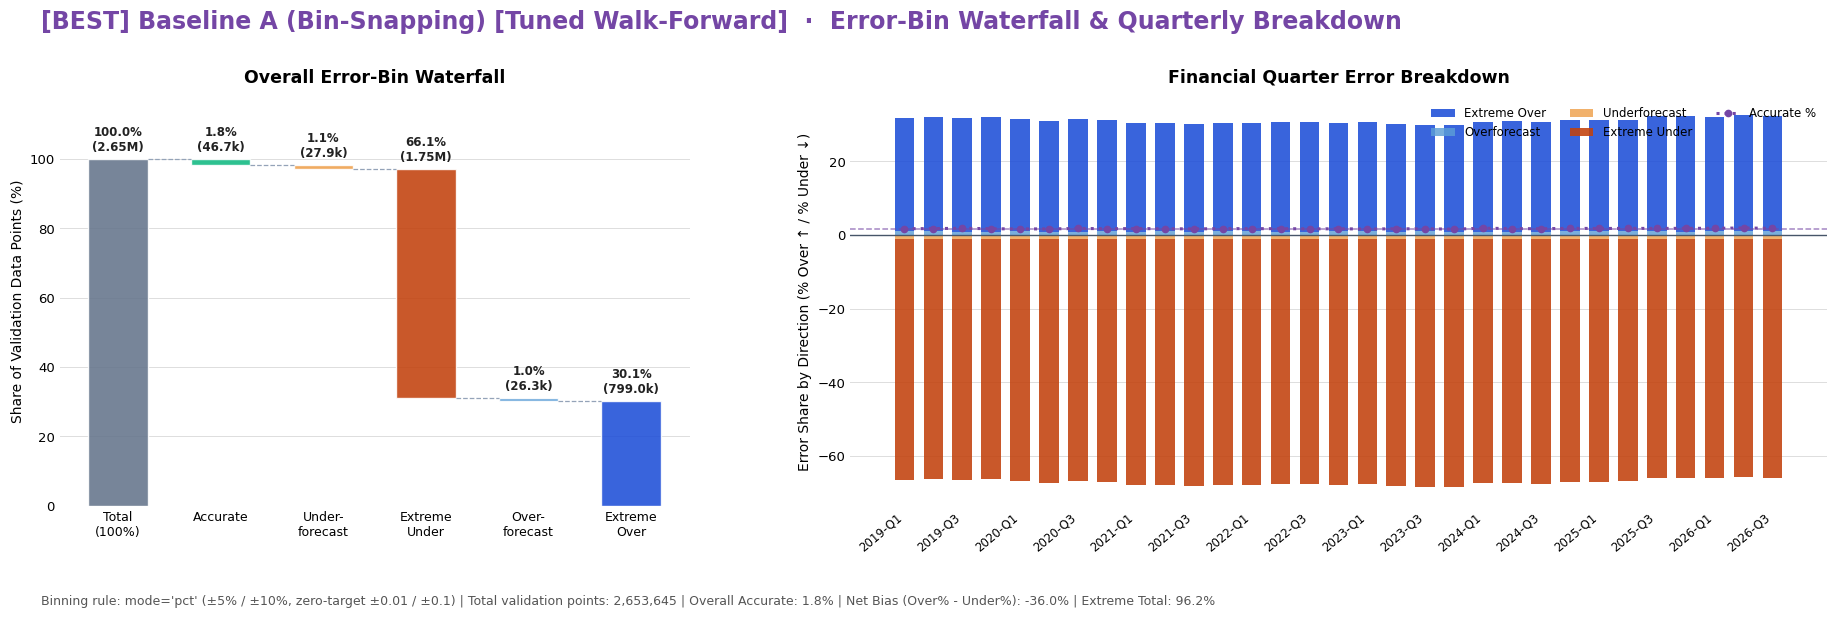

In [16]:
val_dates = val_diag_meta['date'] if 'date' in val_diag_meta.columns else None
model_error_bin_comparison_df = compute_model_error_bin_comparison(
    baseline_results,
    y_validation,
    best_variant_name=best_variant_name,
    mode=error_bin_mode,
    pct_bins=error_pct_bins,
    zero_tols=error_zero_tols,
    abs_bins=error_abs_bins,
)
print('Overall Error-Bin Comparison Across Evaluated Models:')
display(model_error_bin_comparison_df)

waterfall_df = compute_error_bin_waterfall(
    y_validation,
    baseline_results[best_variant_name]['validation_preds'],
    validation_eras,
    dates=val_dates,
    mode=error_bin_mode,
    pct_bins=error_pct_bins,
    zero_tols=error_zero_tols,
    abs_bins=error_abs_bins,
)
print(f'Error-Bin Waterfall Summary Table ({best_variant_name}):')
display(waterfall_df)

waterfall_png_path = (
    results_dir / f'{timestamp}_{experiment_name}_error_bin_waterfall.png'
    if save_results
    else None
)
plot_error_bin_waterfall(
    waterfall_df,
    title=best_variant_name,
    save_path=waterfall_png_path,
)


## Simulated Numerai Staking P&L Dashboard (£)


Meta-model Parquet: Not found (CORR-only proxy fallback)


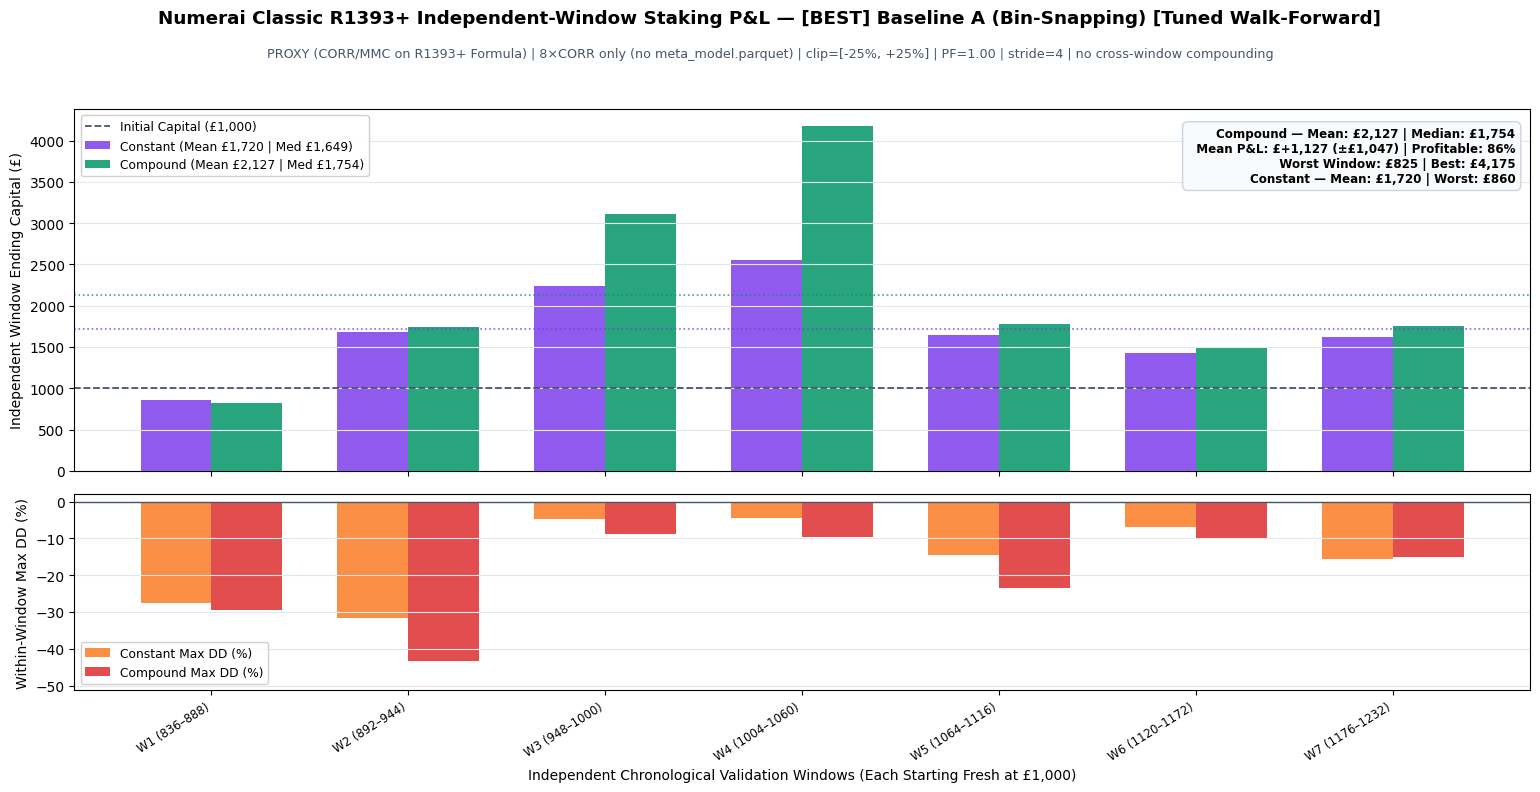

[BEST] Baseline A (Bin-Snapping) [Tuned Walk-Forward] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £2,127 / £1,754 (Worst: £825, Best: £4,175, Profitable: 86%) | Max DD: -43.36% (£-792) | Worst Round: £-410 | Constant Mean: £1,720 (Worst: £860)


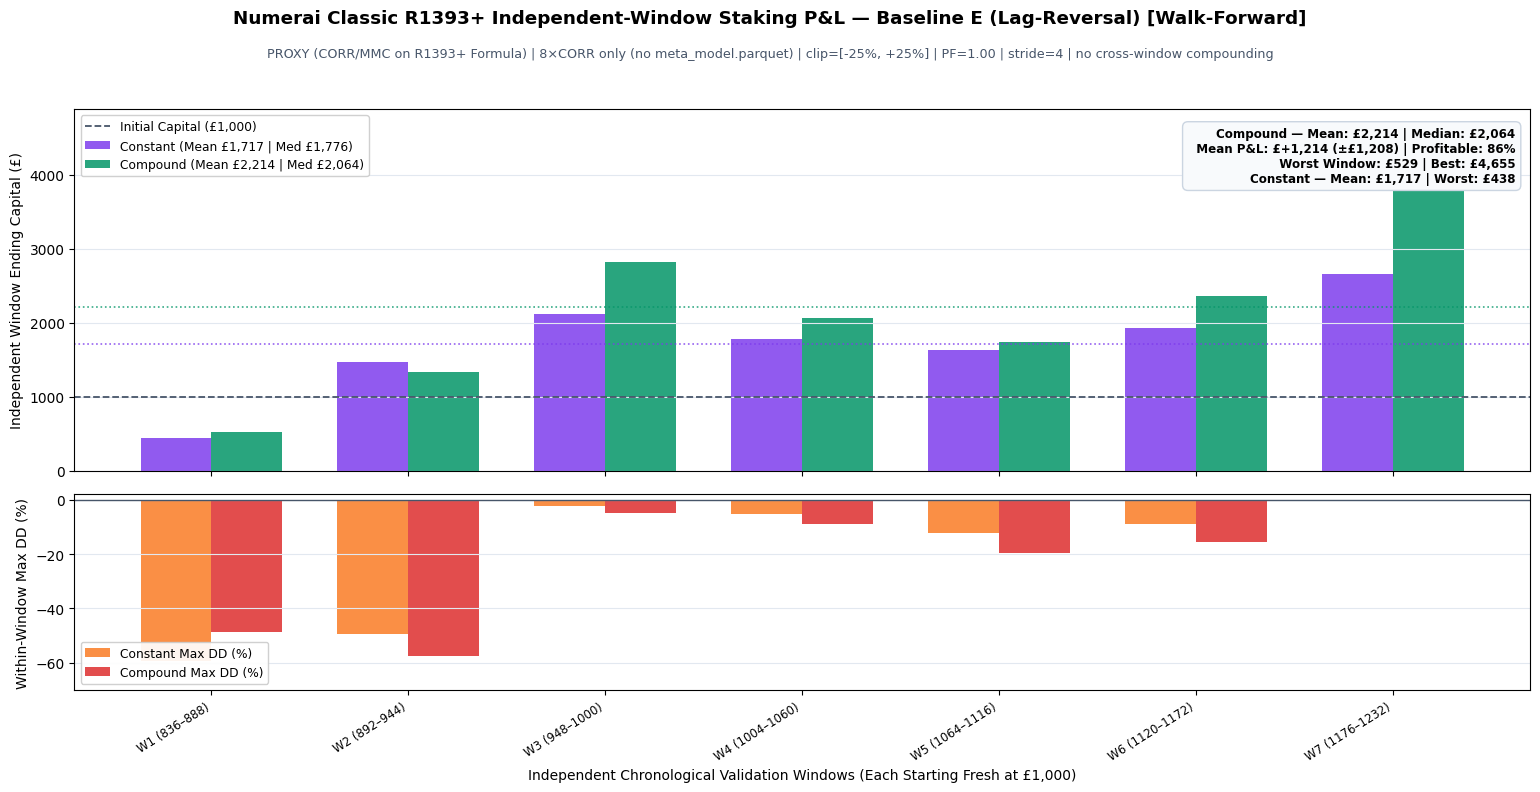

Baseline E (Lag-Reversal) [Walk-Forward] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £2,214 / £2,064 (Worst: £529, Best: £4,655, Profitable: 86%) | Max DD: -57.75% (£-989) | Worst Round: £-334 | Constant Mean: £1,717 (Worst: £438)


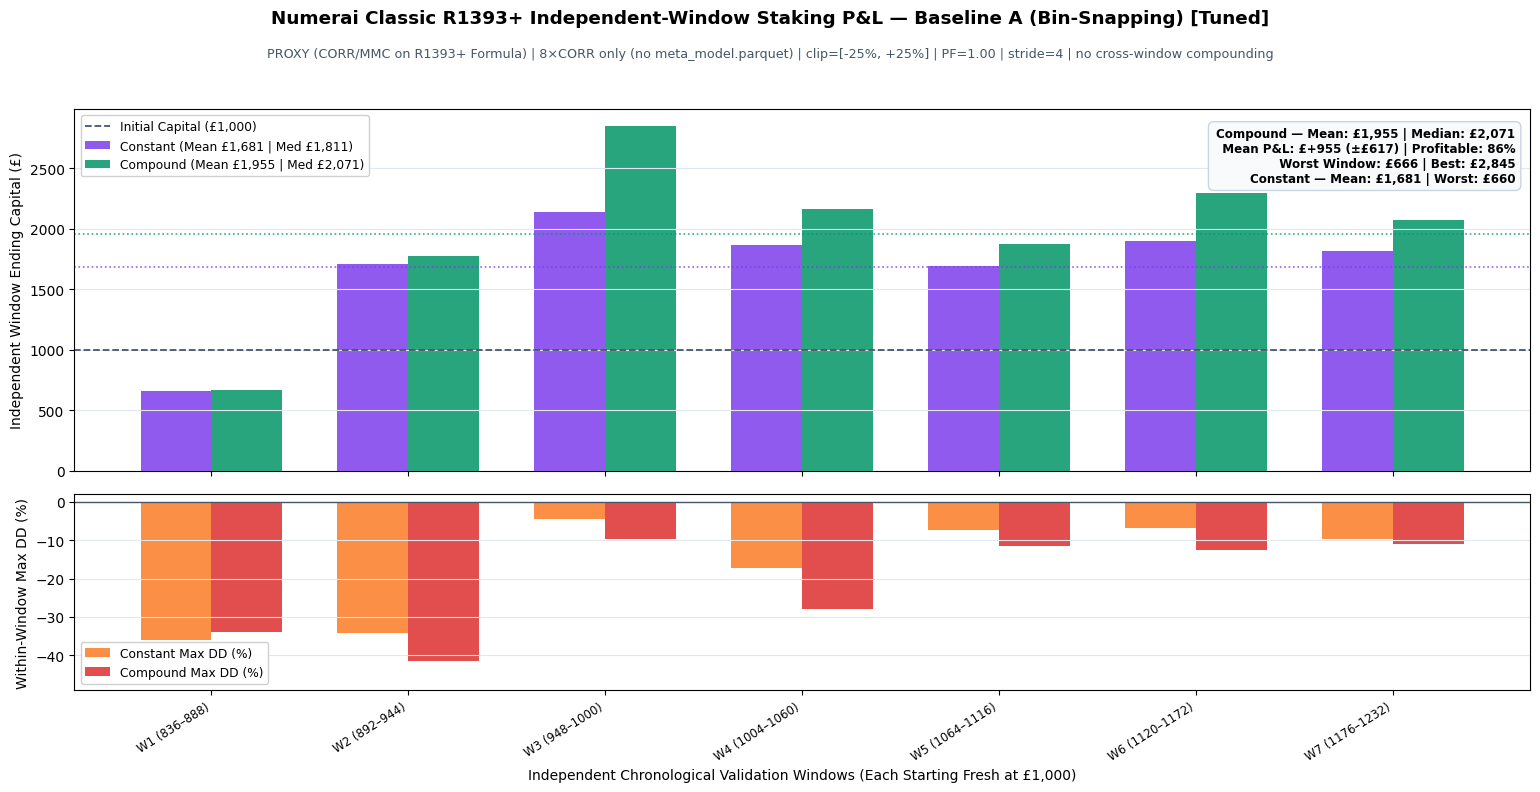

Baseline A (Bin-Snapping) [Tuned] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £1,955 / £2,071 (Worst: £666, Best: £2,845, Profitable: 86%) | Max DD: -41.52% (£-630) | Worst Round: £-279 | Constant Mean: £1,681 (Worst: £660)


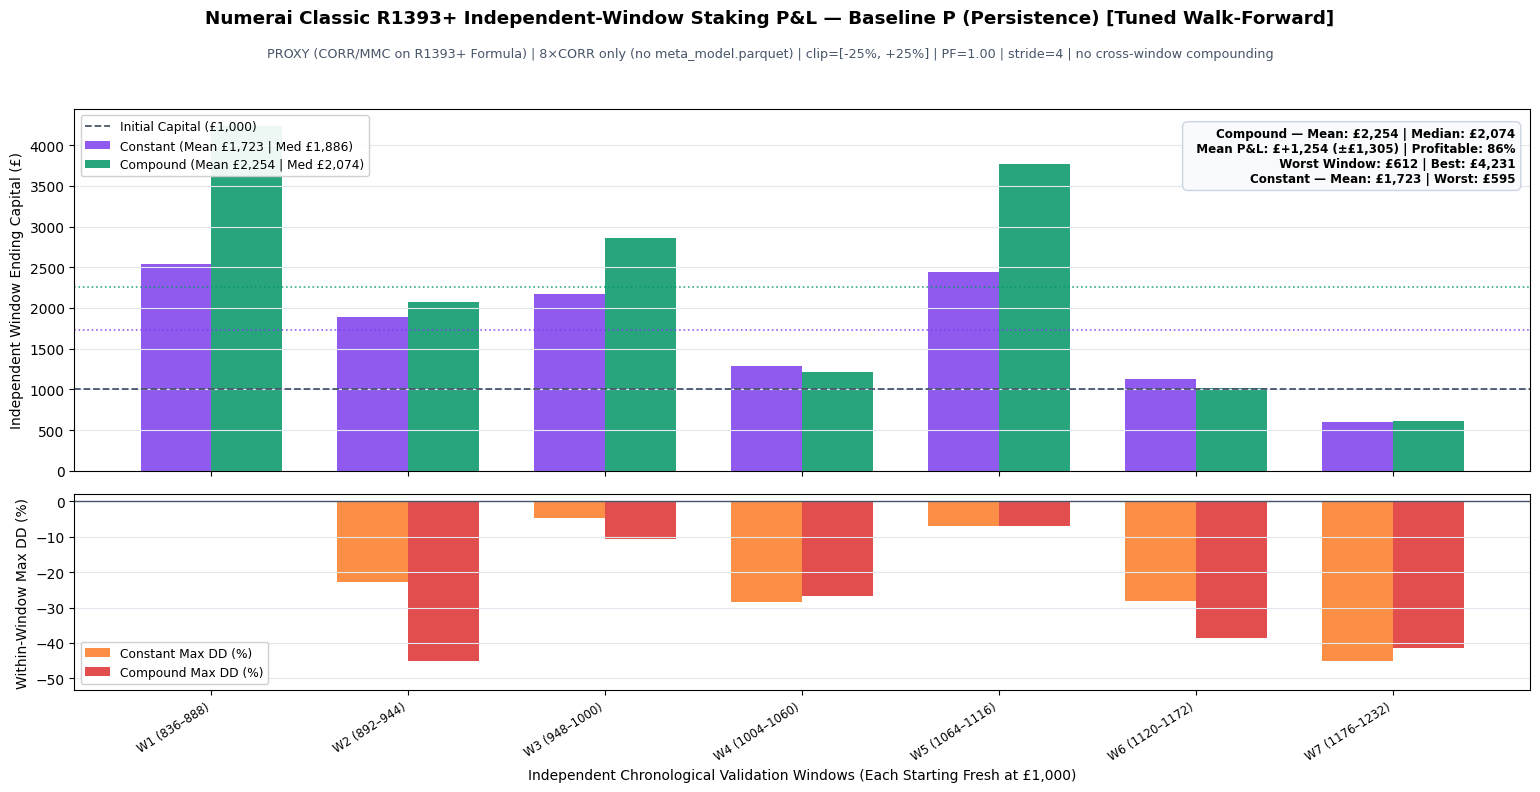

Baseline P (Persistence) [Tuned Walk-Forward] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £2,254 / £2,074 (Worst: £612, Best: £4,231, Profitable: 86%) | Max DD: -45.12% (£-1,641) | Worst Round: £-573 | Constant Mean: £1,723 (Worst: £595)


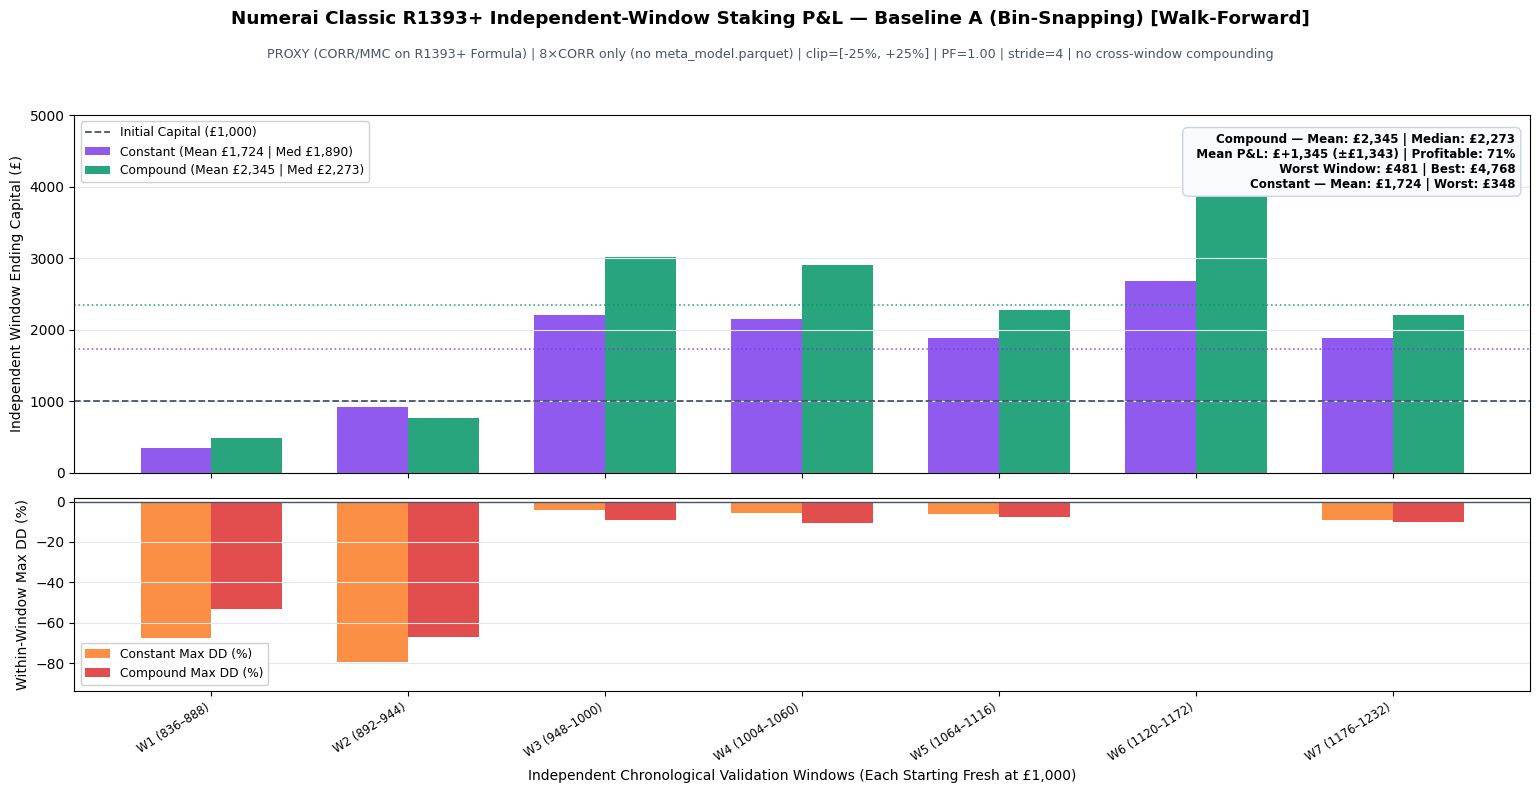

Baseline A (Bin-Snapping) [Walk-Forward] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £2,345 / £2,273 (Worst: £481, Best: £4,768, Profitable: 71%) | Max DD: -67.06% (£-865) | Worst Round: £-283 | Constant Mean: £1,724 (Worst: £348)


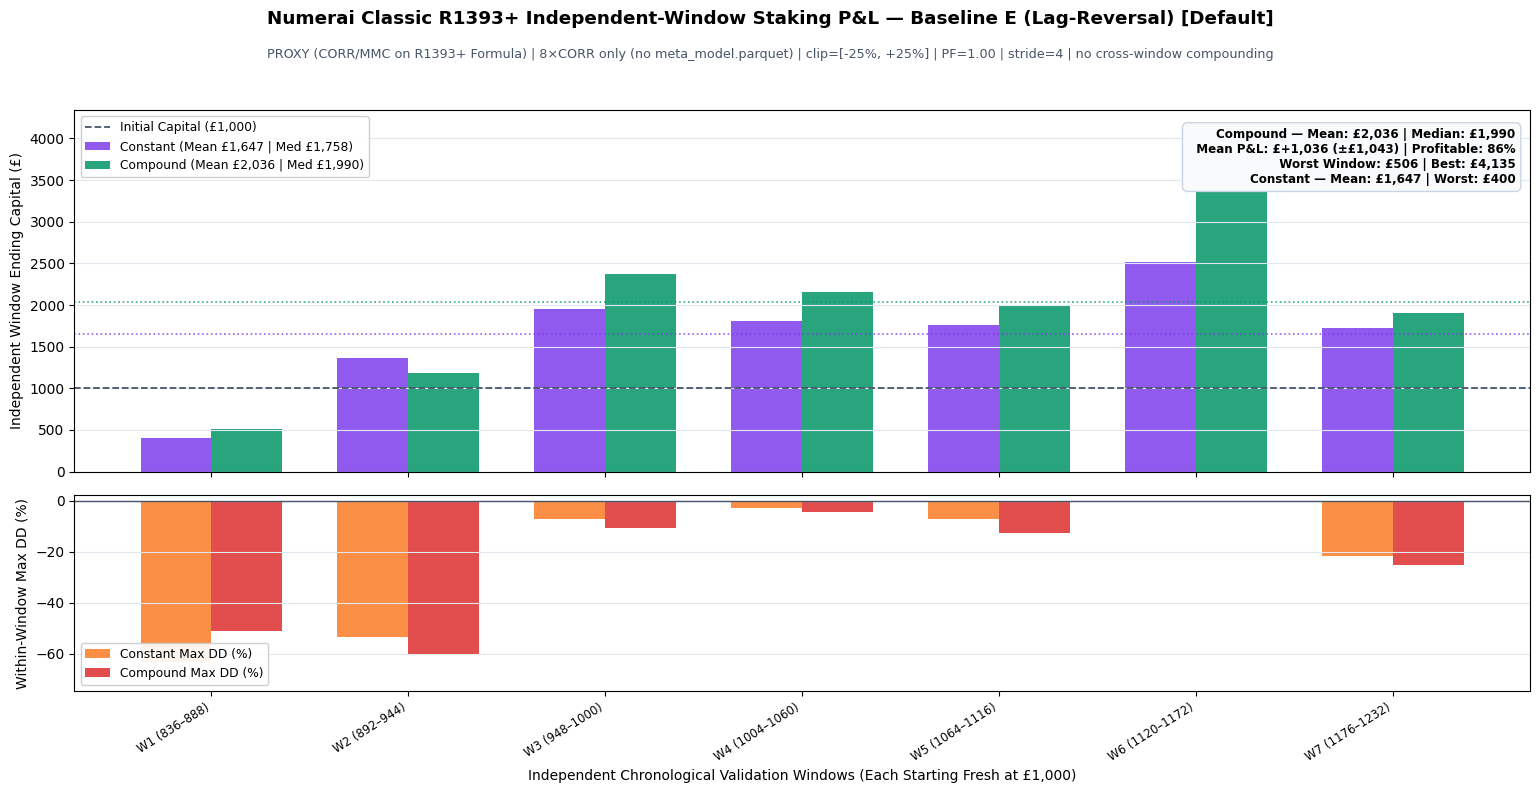

Baseline E (Lag-Reversal) [Default] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £2,036 / £1,990 (Worst: £506, Best: £4,135, Profitable: 86%) | Max DD: -60.68% (£-1,032) | Worst Round: £-321 | Constant Mean: £1,647 (Worst: £400)


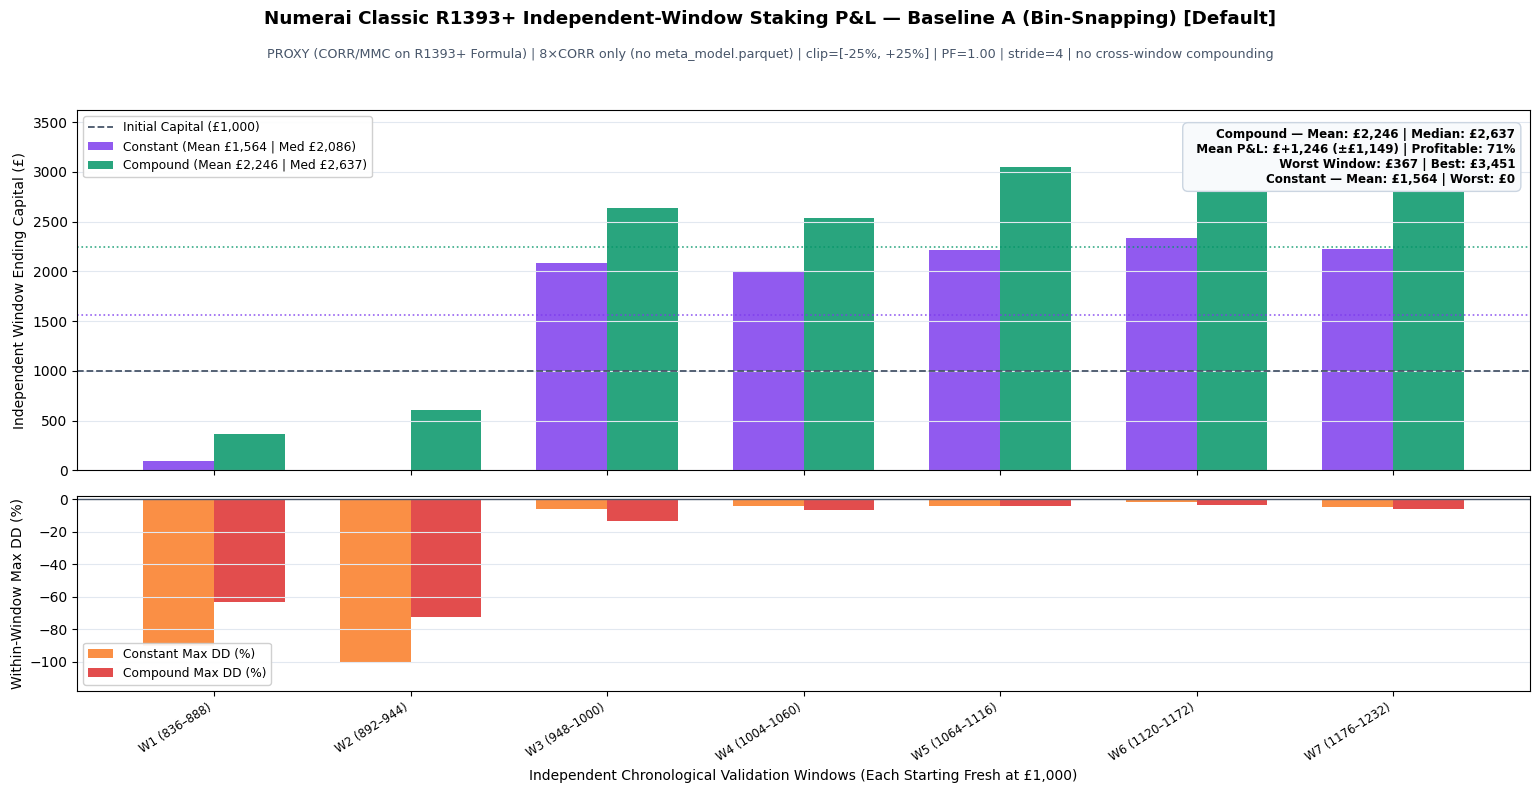

Baseline A (Bin-Snapping) [Default] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £2,246 / £2,637 (Worst: £367, Best: £3,451, Profitable: 71%) | Max DD: -72.31% (£-839) | Worst Round: £-344 | Constant Mean: £1,564 (Worst: £0)


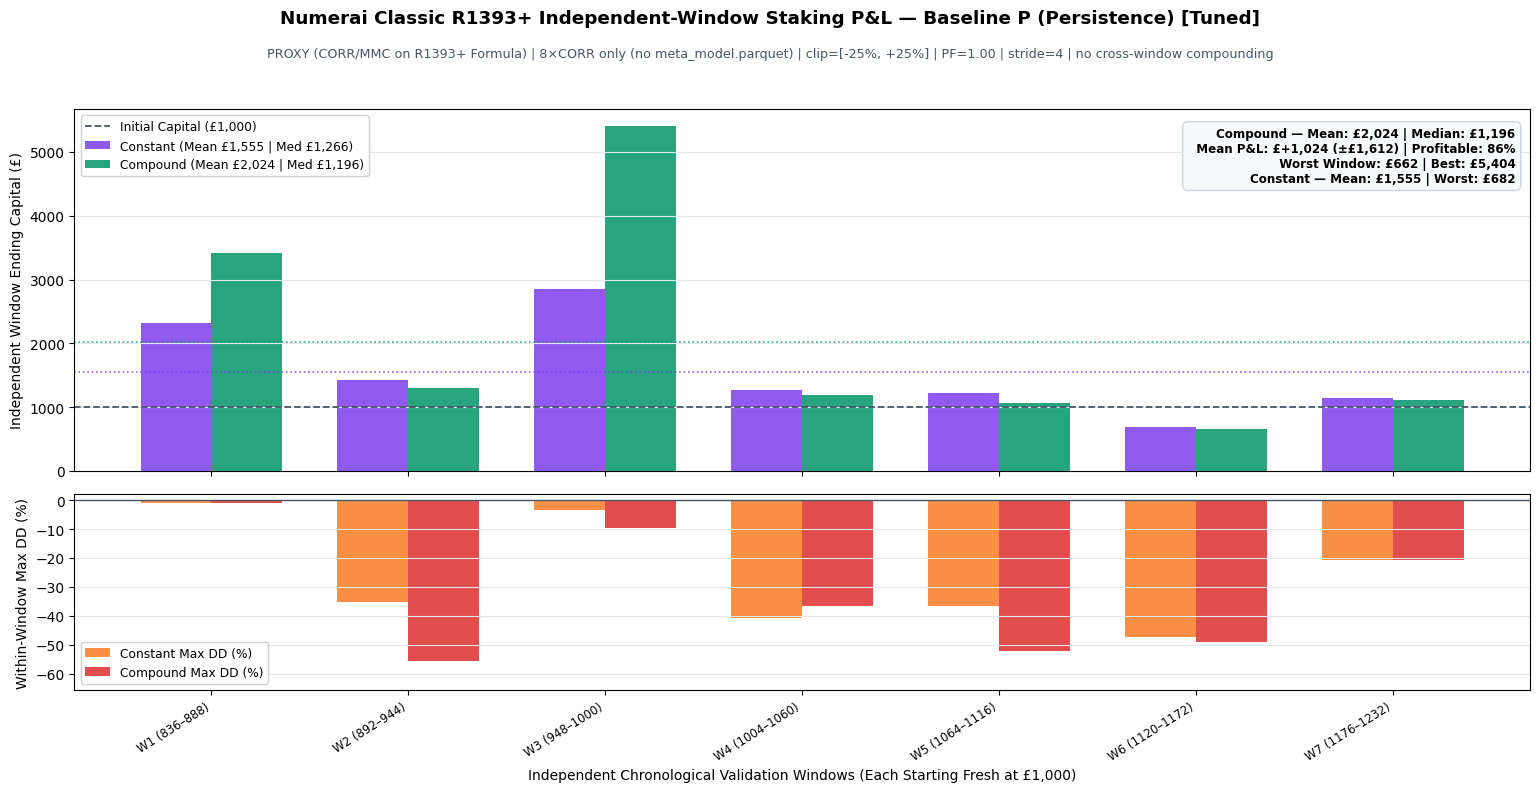

Baseline P (Persistence) [Tuned] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £2,024 / £1,196 (Worst: £662, Best: £5,404, Profitable: 86%) | Max DD: -55.56% (£-1,483) | Worst Round: £-580 | Constant Mean: £1,555 (Worst: £682)


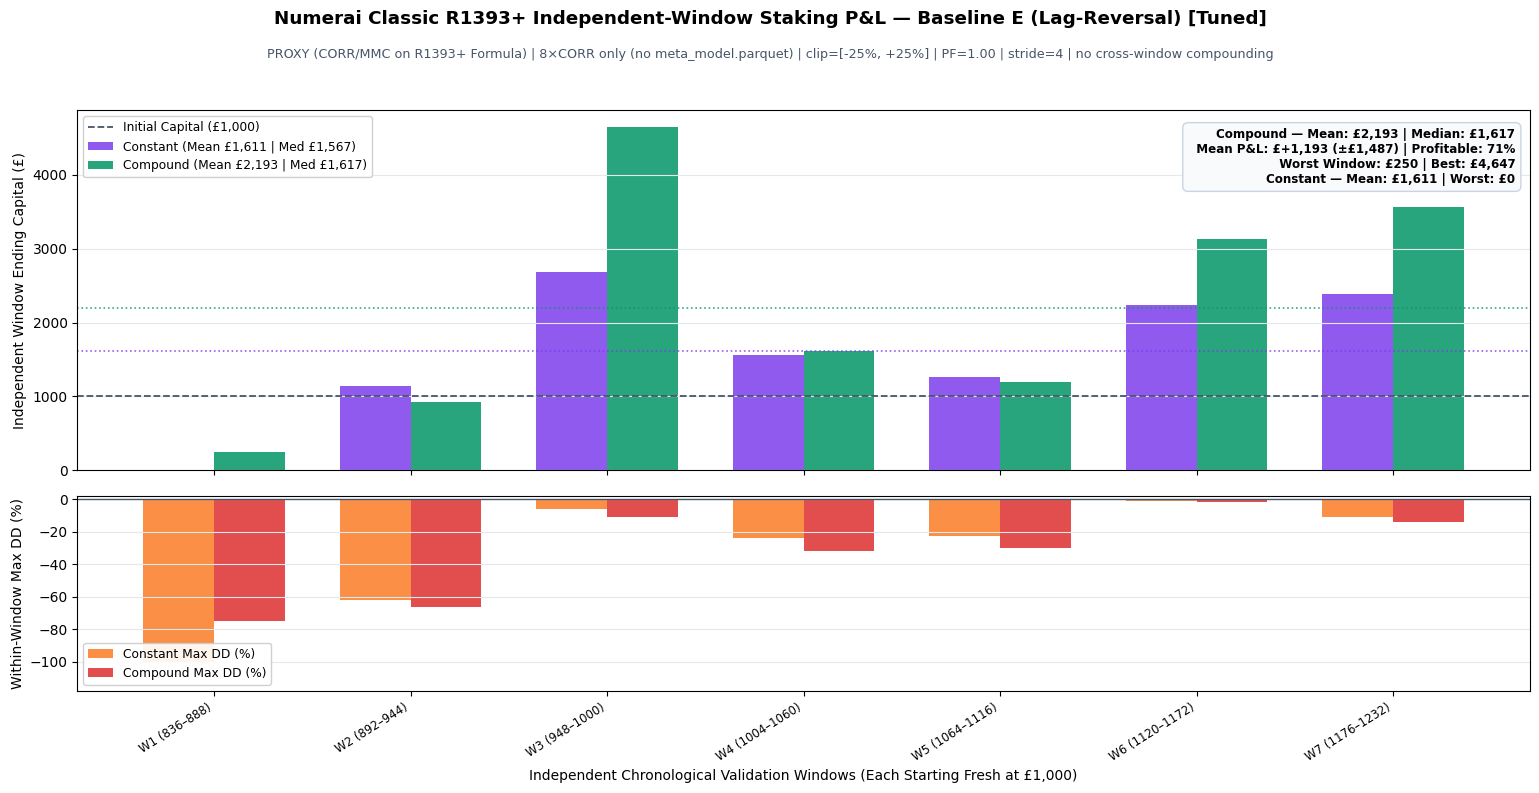

Baseline E (Lag-Reversal) [Tuned] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £2,193 / £1,617 (Worst: £250, Best: £4,647, Profitable: 71%) | Max DD: -75.01% (£-1,117) | Worst Round: £-318 | Constant Mean: £1,611 (Worst: £0)


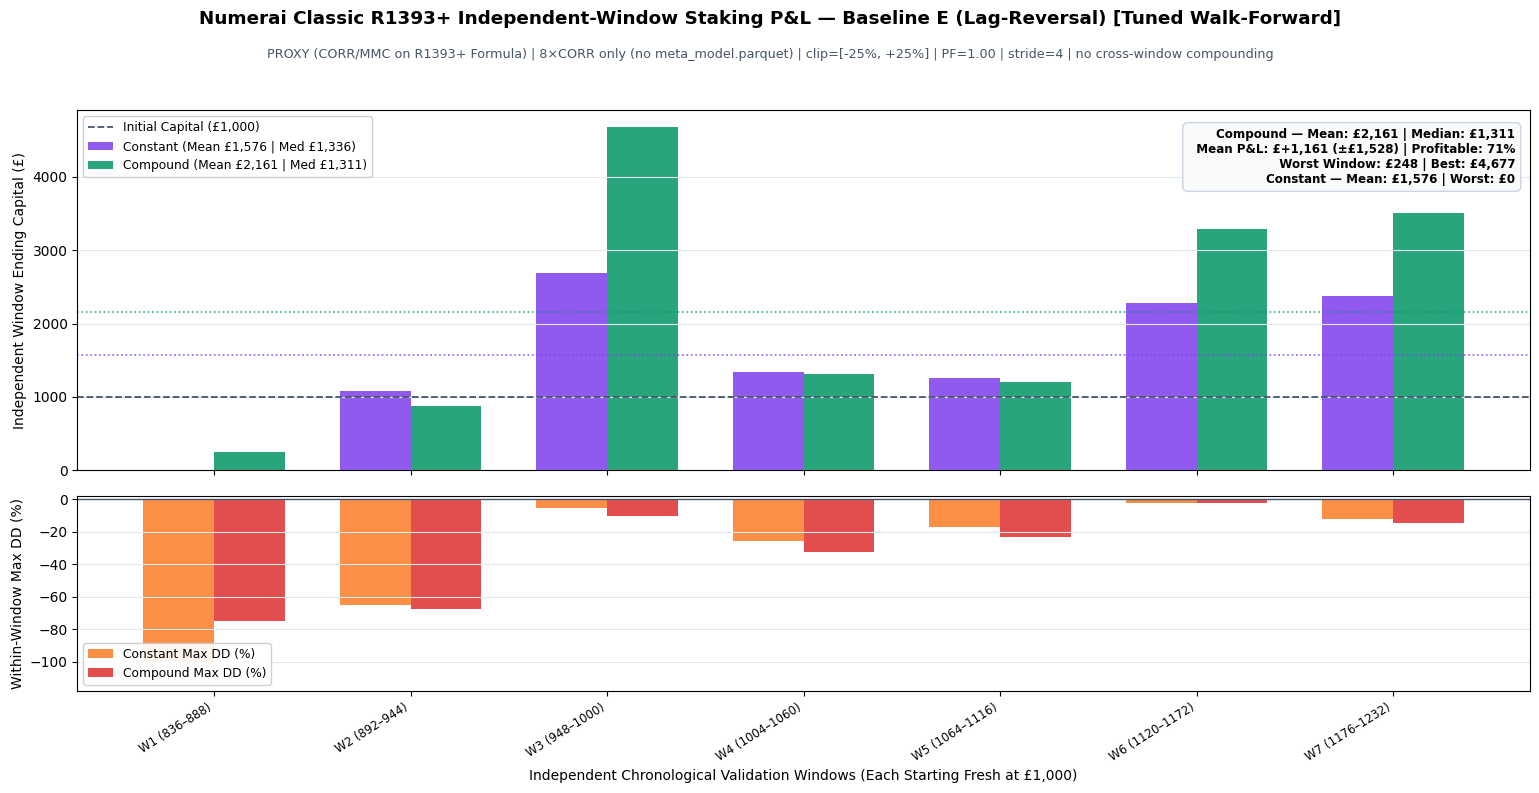

Baseline E (Lag-Reversal) [Tuned Walk-Forward] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £2,161 / £1,311 (Worst: £248, Best: £4,677, Profitable: 71%) | Max DD: -75.22% (£-1,110) | Worst Round: £-301 | Constant Mean: £1,576 (Worst: £0)


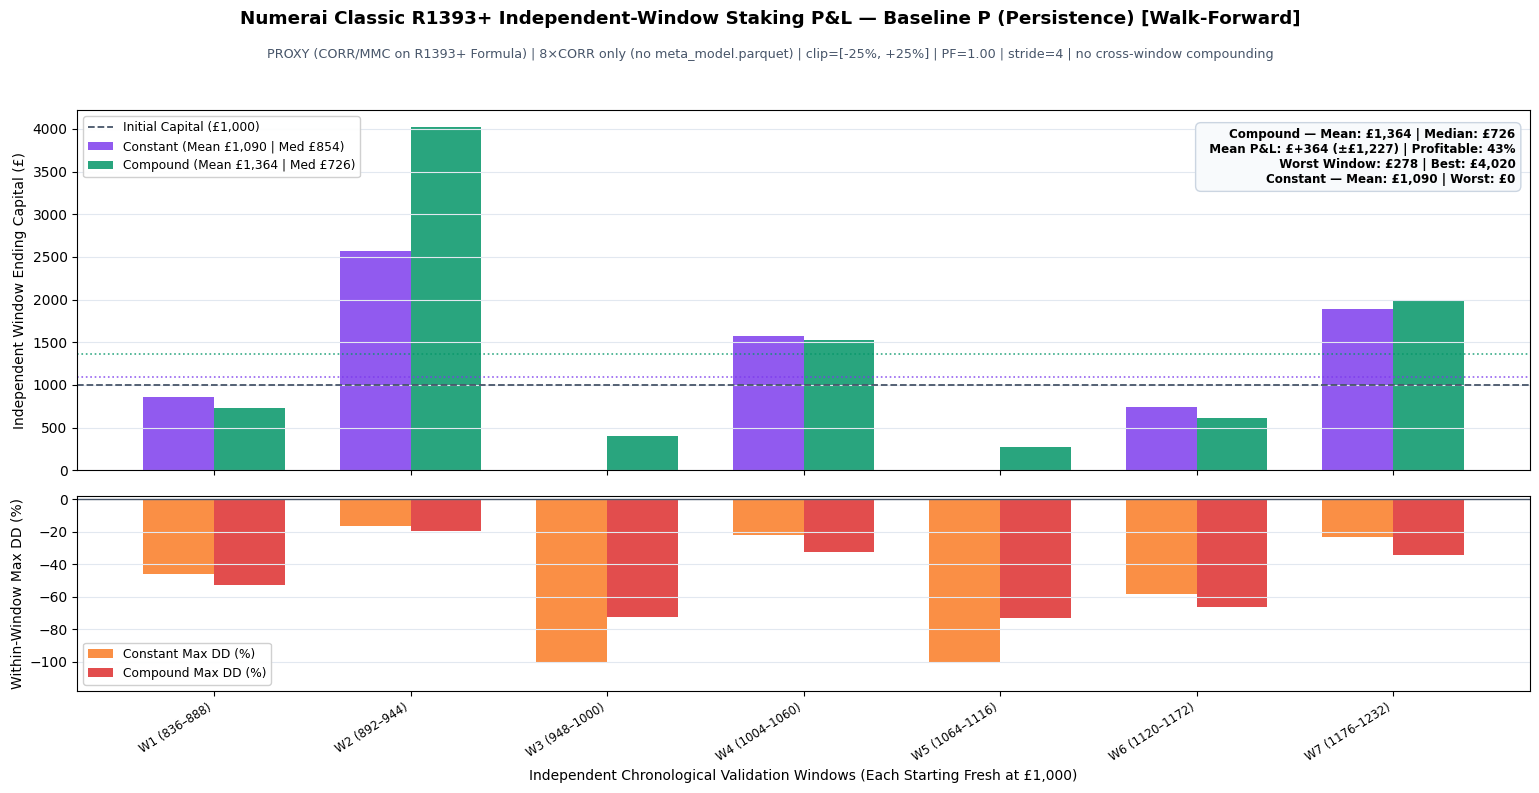

Baseline P (Persistence) [Walk-Forward] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £1,364 / £726 (Worst: £278, Best: £4,020, Profitable: 43%) | Max DD: -73.06% (£-1,133) | Worst Round: £-401 | Constant Mean: £1,090 (Worst: £0)


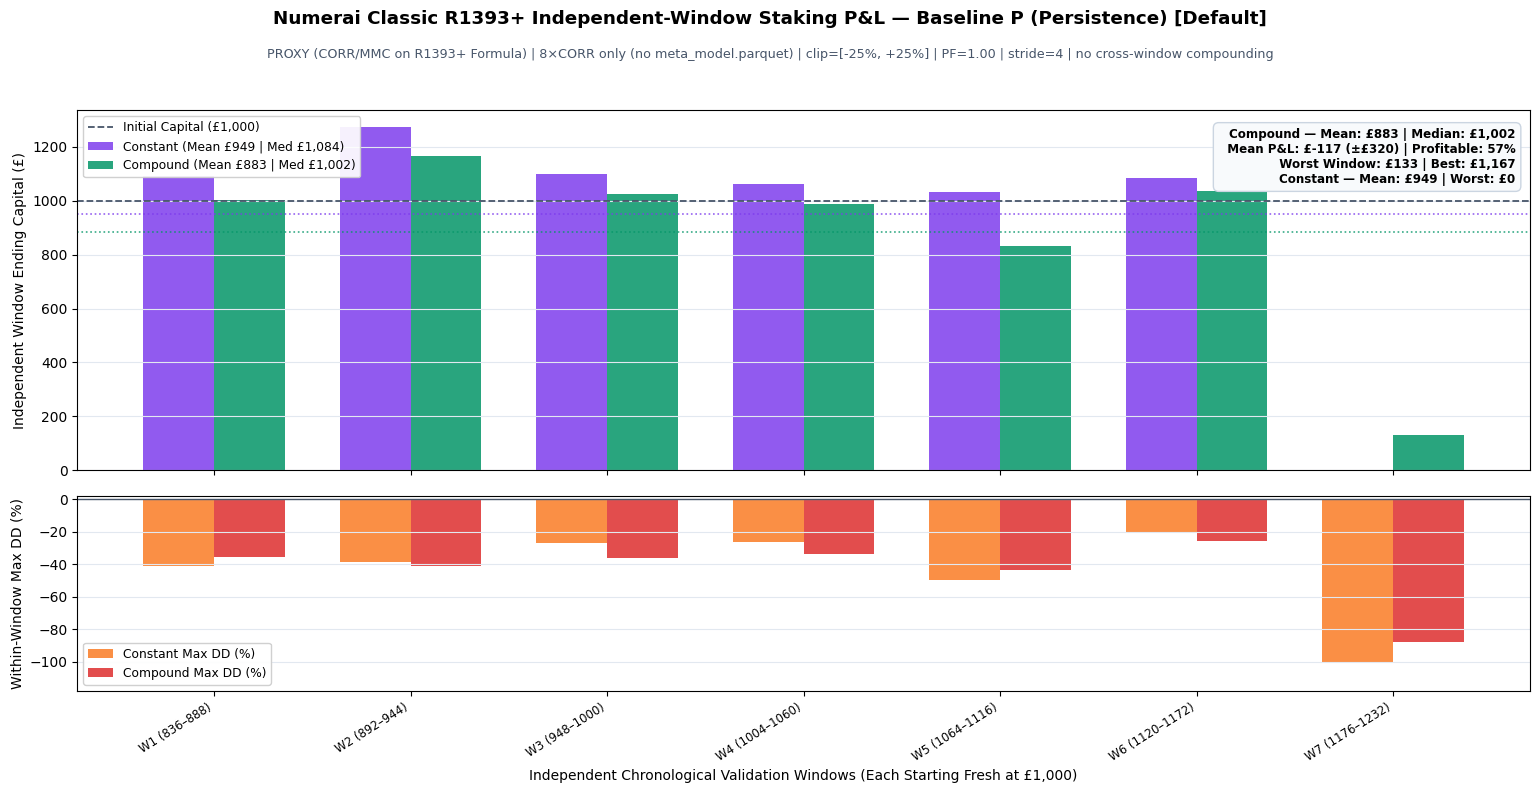

Baseline P (Persistence) [Default] (7 independent windows, R1393+ Proxy) | Compound Mean/Med: £883 / £1,002 (Worst: £133, Best: £1,167, Profitable: 57%) | Max DD: -88.06% (£-881) | Worst Round: £-285 | Constant Mean: £949 (Worst: £0)


In [17]:
meta_model_candidates = [
    Path(workspace_root) / data_folder / data_version / 'meta_model.parquet',
    Path(workspace_root) / data_folder / 'meta_model.parquet',
]
if Path('/kaggle/input').is_dir():
    meta_model_candidates.extend(sorted(Path('/kaggle/input').rglob('meta_model.parquet')))
meta_model_path = next((p for p in meta_model_candidates if p.is_file()), None)
val_mmc_df = val_diag_meta.assign(**{TARGET_COL: y_validation.to_numpy(dtype=np.float32)})
print('Meta-model Parquet:', meta_model_path if meta_model_path is not None else 'Not found (CORR-only proxy fallback)')

stake_pnl_by_variant = {}
variant_era_mmc_by_variant = {}
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    variant_era_corrs = baseline_results[variant_name]['validation_era_corrs']
    variant_era_mmc = compute_per_era_mmc(
        val_mmc_df,
        baseline_results[variant_name]['validation_preds'],
        meta_model_path=meta_model_path,
        era_col=ERA_COL,
        target_col=TARGET_COL,
    )
    variant_era_mmc_by_variant[variant_name] = variant_era_mmc
    pnl_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_stake_pnl_dashboard.png'
        if save_results
        else None
    )
    title_label = f'[BEST] {variant_name}' if is_best_variant else variant_name
    stake_pnl_by_variant[variant_name] = plot_stake_pnl_dashboard(
        variant_era_corrs,
        per_era_mmc=variant_era_mmc,
        title=title_label,
        initial_stake=1000.0,
        corr_weight=8.0,
        mmc_weight=32.0,
        payout_factor=1.0,
        clip_min=-0.25,
        clip_max=0.25,
        stride=4,
        window_rounds=13,
        score_basis='corr_mmc_proxy',
        save_path=pnl_save_path,
    )
    v_pnl = stake_pnl_by_variant[variant_name]
    c_sum = v_pnl['constant_summary']
    print(
        f"{title_label} ({v_pnl['n_windows']} independent windows, R1393+ Proxy) | "
        f"Compound Mean/Med: £{v_pnl['mean_ending_capital']:,.0f} / £{v_pnl['median_ending_capital']:,.0f} "
        f"(Worst: £{v_pnl['worst_window_ending_capital']:,.0f}, Best: £{v_pnl['best_window_ending_capital']:,.0f}, "
        f"Profitable: {v_pnl['profitable_windows_pct']:.0f}%) | "
        f"Max DD: {v_pnl['max_drawdown_pct']:.2f}% (£{v_pnl['max_drawdown_gbp']:,.0f}) | Worst Round: £{v_pnl['worst_era_gbp']:+,.0f} | "
        f"Constant Mean: £{c_sum['mean_ending_capital']:,.0f} (Worst: £{c_sum['worst_window_ending_capital']:,.0f})"
    )
best_stake_pnl = stake_pnl_by_variant[best_variant_name]


## Monte Carlo Block-Bootstrap Risk Analysis (£)


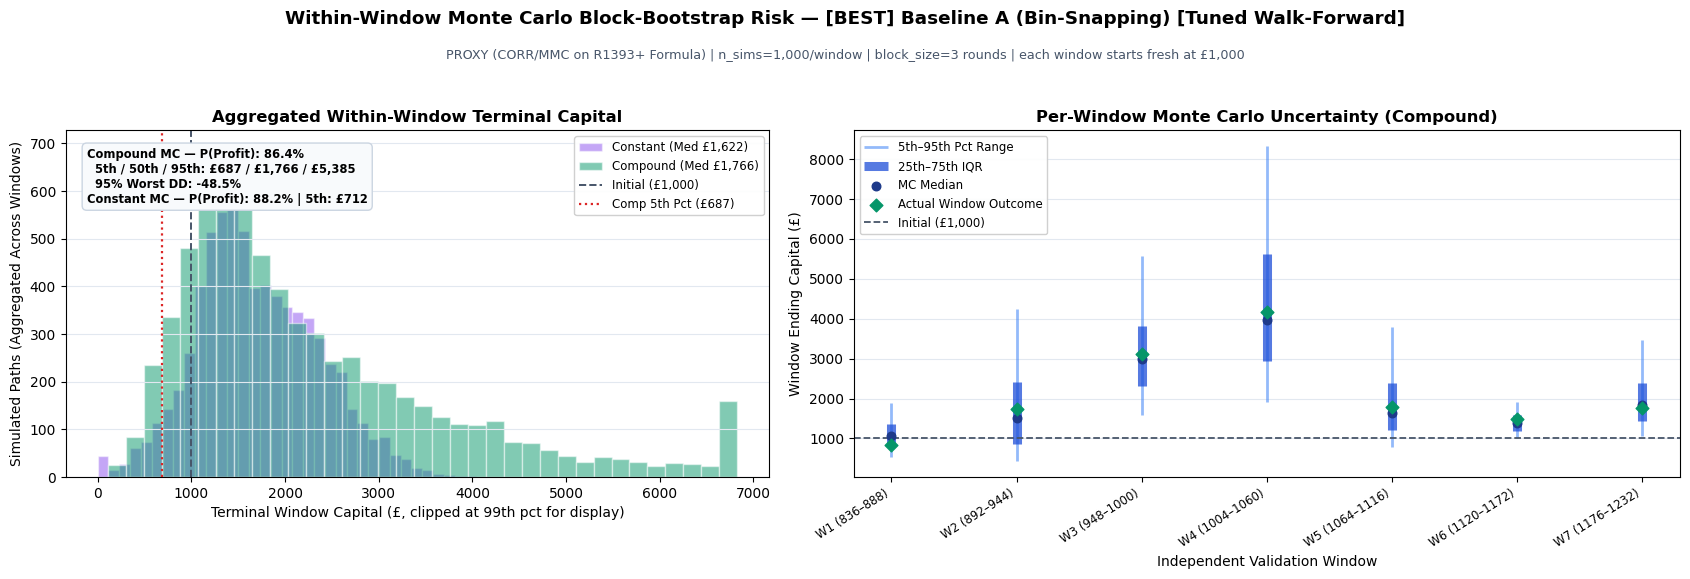

[BEST] Baseline A (Bin-Snapping) [Tuned Walk-Forward] [Within-Window MC] | Compound P(Profit): 86.4% | 5th/50th/95th: £687 / £1,766 / £5,385 | 95% Worst DD: -48.5% | Constant P(Profit): 88.2%


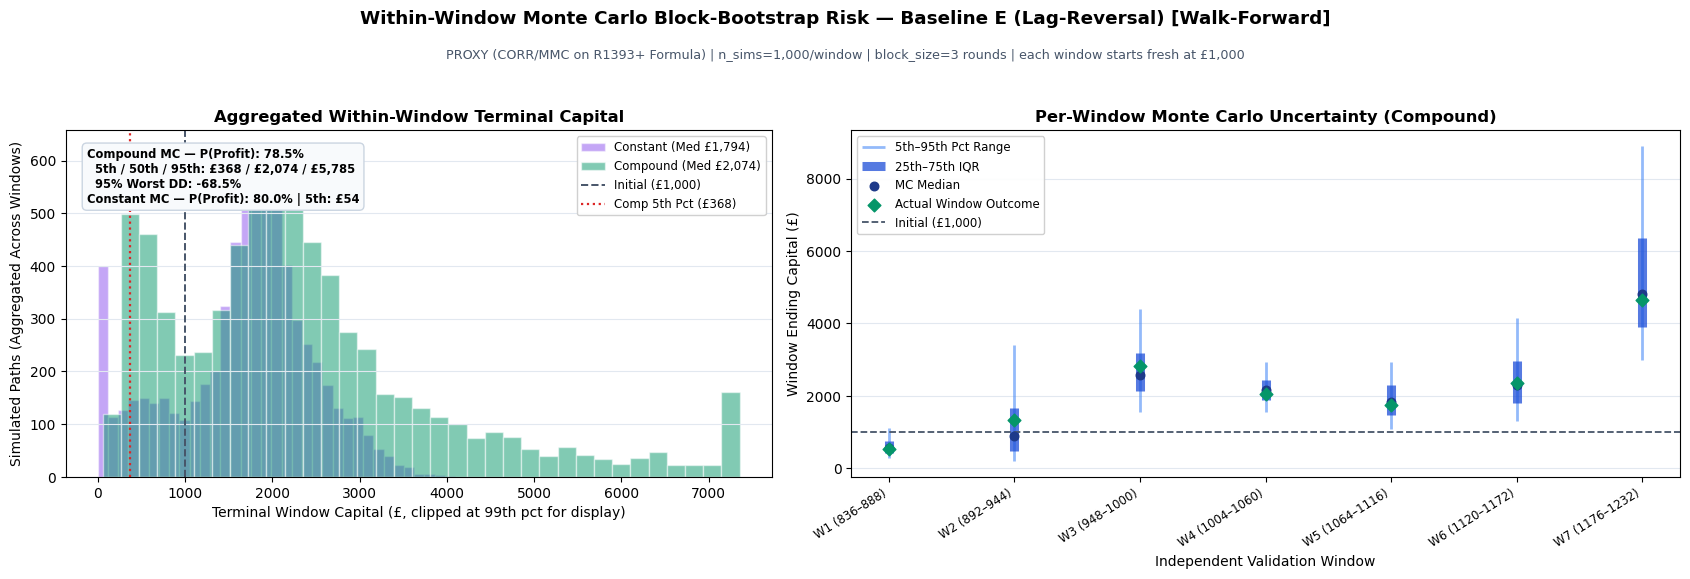

Baseline E (Lag-Reversal) [Walk-Forward] [Within-Window MC] | Compound P(Profit): 78.5% | 5th/50th/95th: £368 / £2,074 / £5,785 | 95% Worst DD: -68.5% | Constant P(Profit): 80.0%


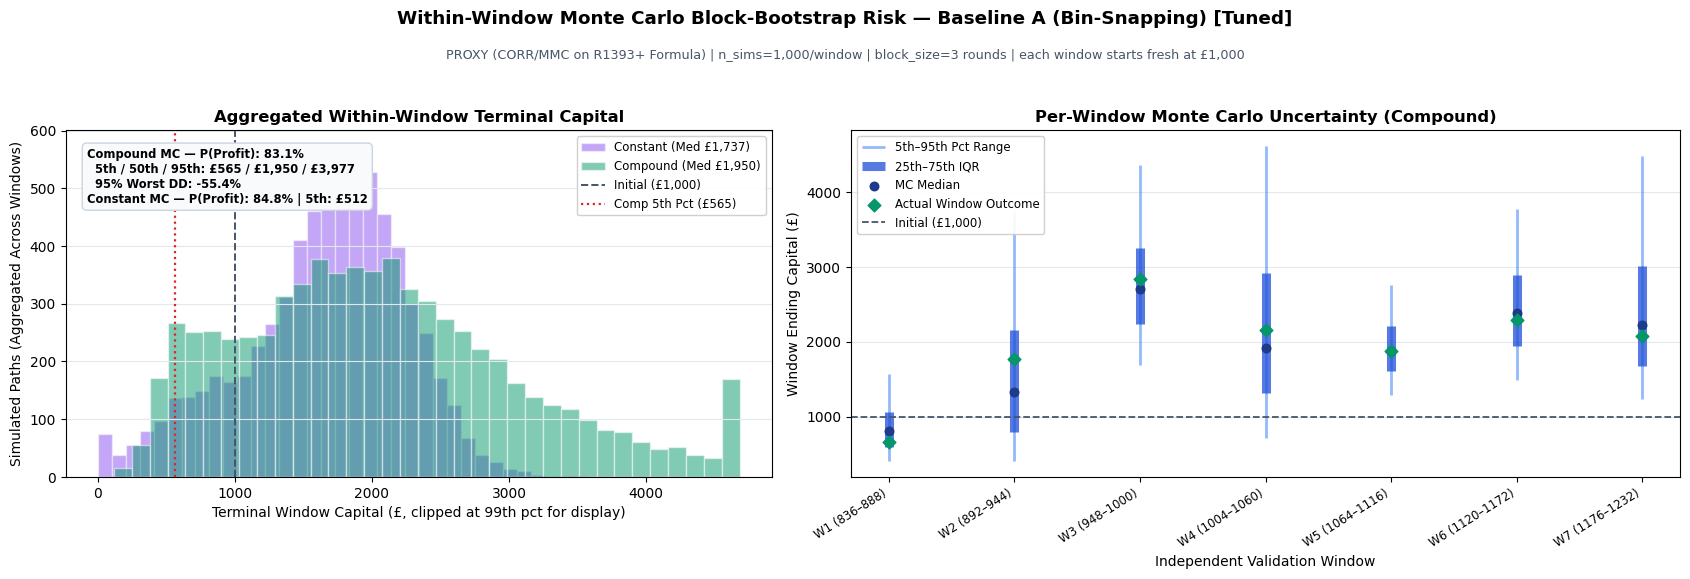

Baseline A (Bin-Snapping) [Tuned] [Within-Window MC] | Compound P(Profit): 83.1% | 5th/50th/95th: £565 / £1,950 / £3,977 | 95% Worst DD: -55.4% | Constant P(Profit): 84.8%


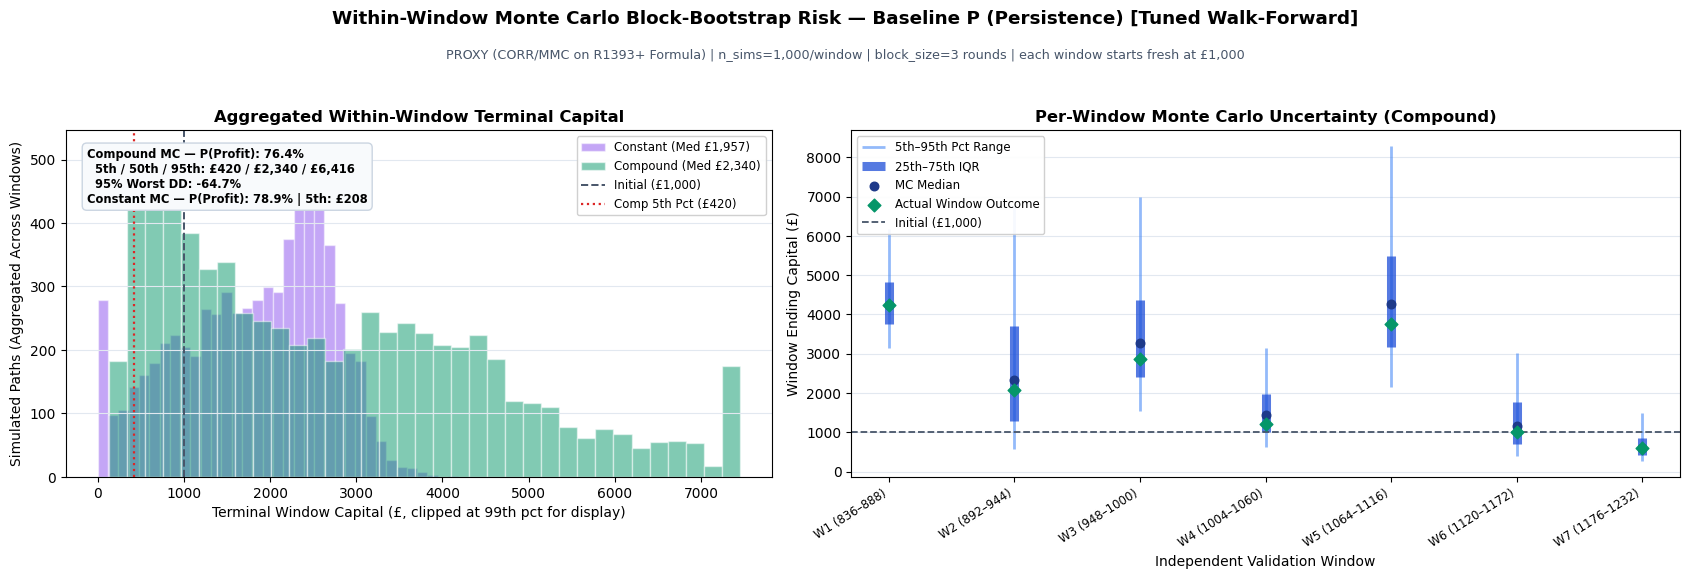

Baseline P (Persistence) [Tuned Walk-Forward] [Within-Window MC] | Compound P(Profit): 76.4% | 5th/50th/95th: £420 / £2,340 / £6,416 | 95% Worst DD: -64.7% | Constant P(Profit): 78.9%


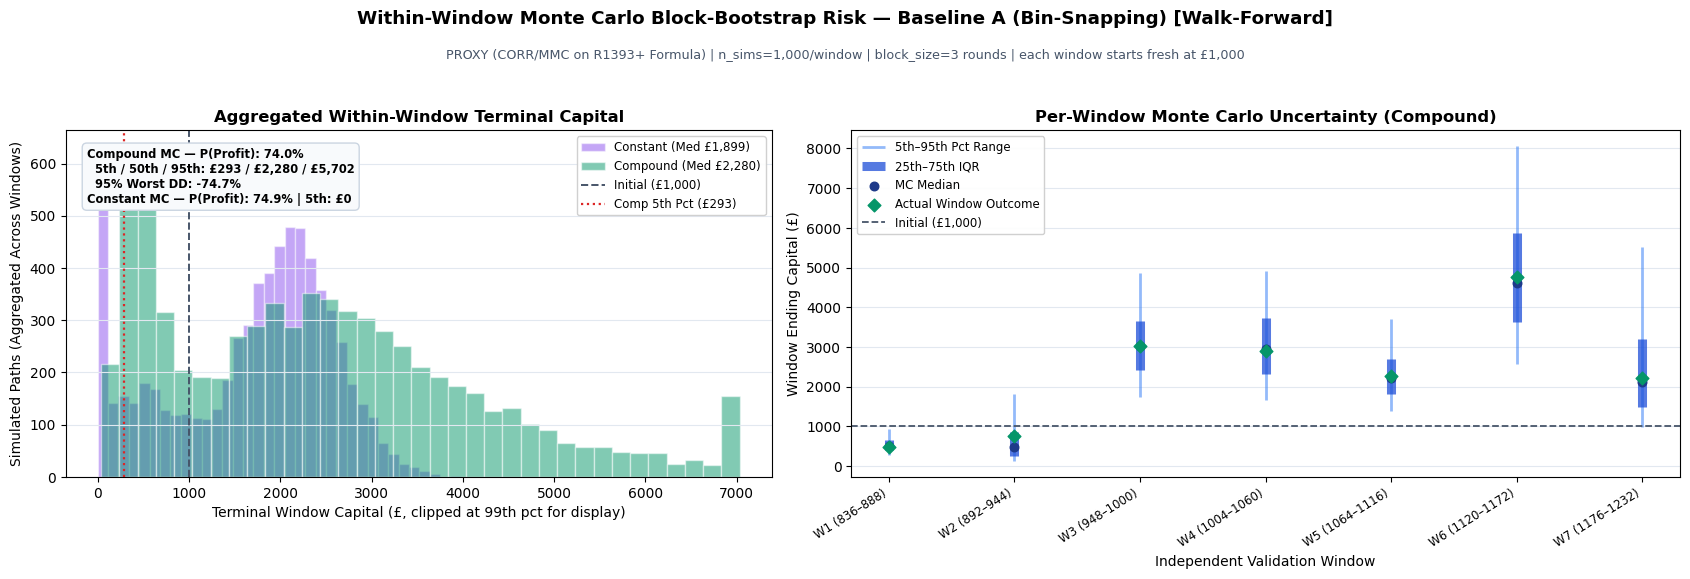

Baseline A (Bin-Snapping) [Walk-Forward] [Within-Window MC] | Compound P(Profit): 74.0% | 5th/50th/95th: £293 / £2,280 / £5,702 | 95% Worst DD: -74.7% | Constant P(Profit): 74.9%


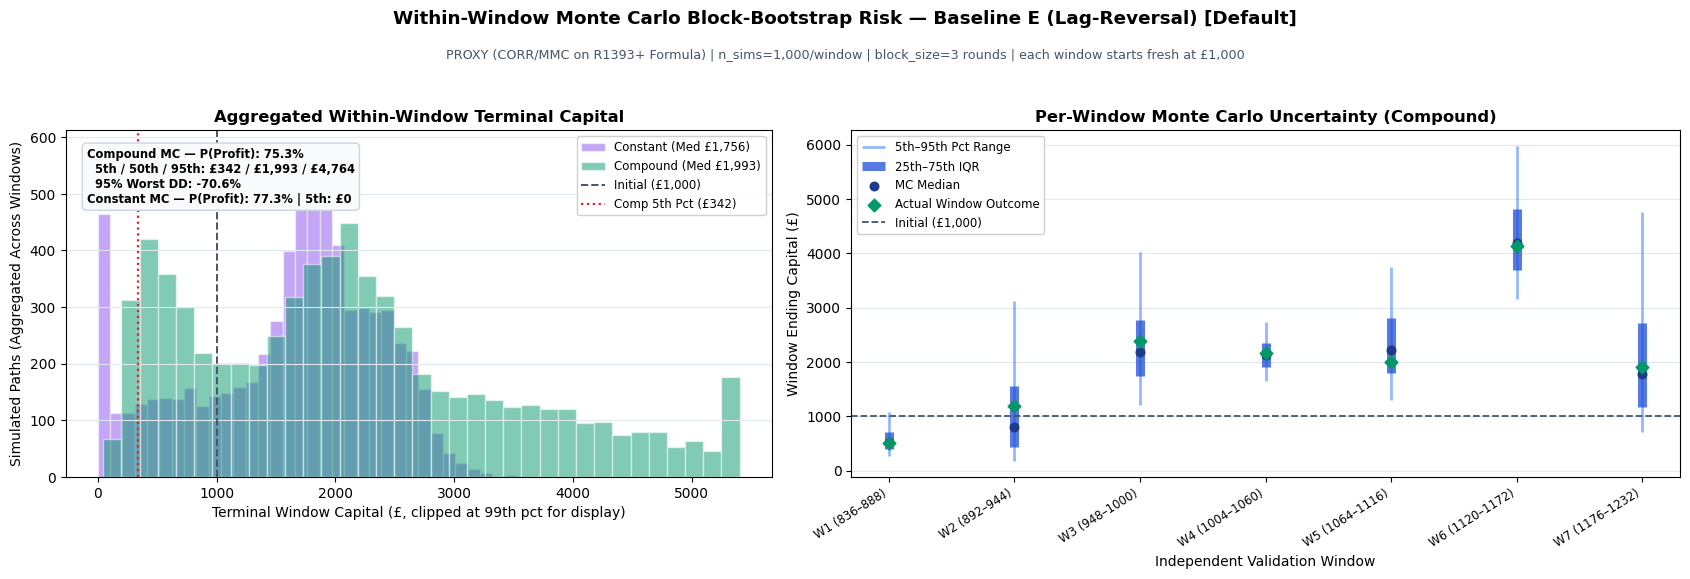

Baseline E (Lag-Reversal) [Default] [Within-Window MC] | Compound P(Profit): 75.3% | 5th/50th/95th: £342 / £1,993 / £4,764 | 95% Worst DD: -70.6% | Constant P(Profit): 77.3%


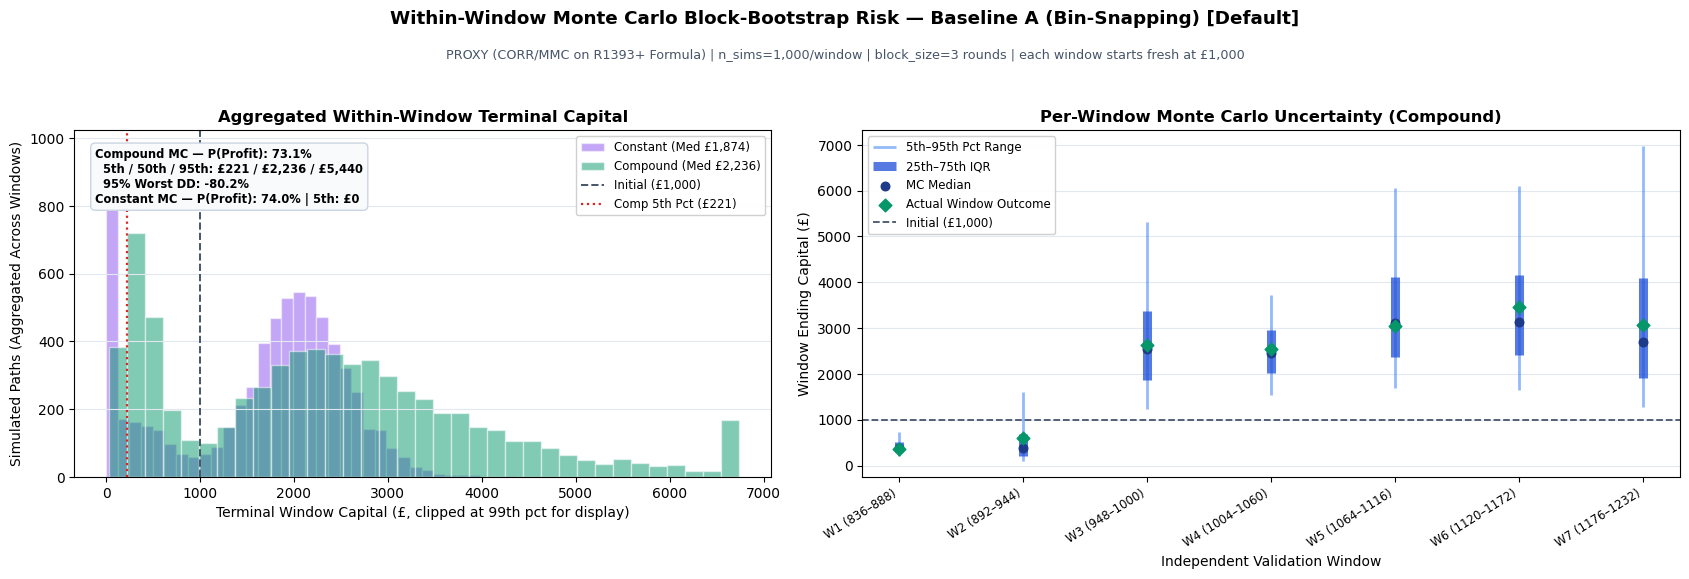

Baseline A (Bin-Snapping) [Default] [Within-Window MC] | Compound P(Profit): 73.1% | 5th/50th/95th: £221 / £2,236 / £5,440 | 95% Worst DD: -80.2% | Constant P(Profit): 74.0%


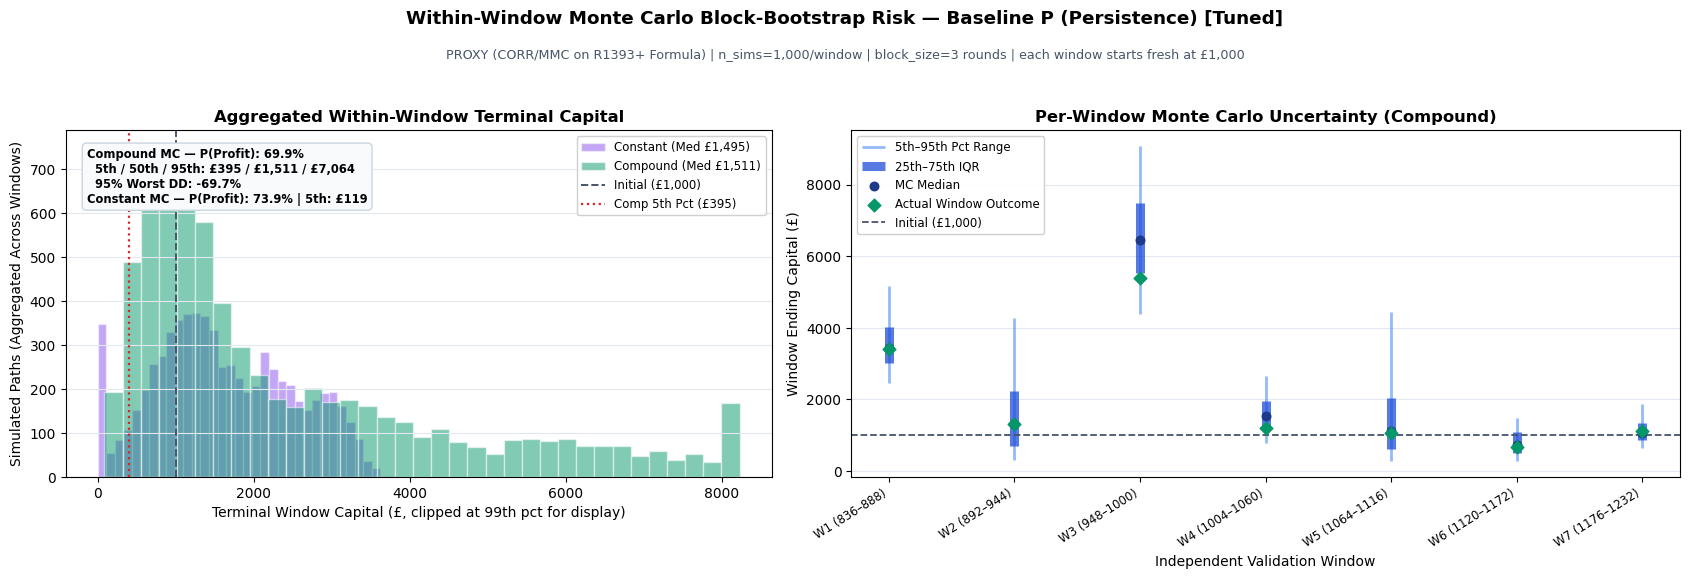

Baseline P (Persistence) [Tuned] [Within-Window MC] | Compound P(Profit): 69.9% | 5th/50th/95th: £395 / £1,511 / £7,064 | 95% Worst DD: -69.7% | Constant P(Profit): 73.9%


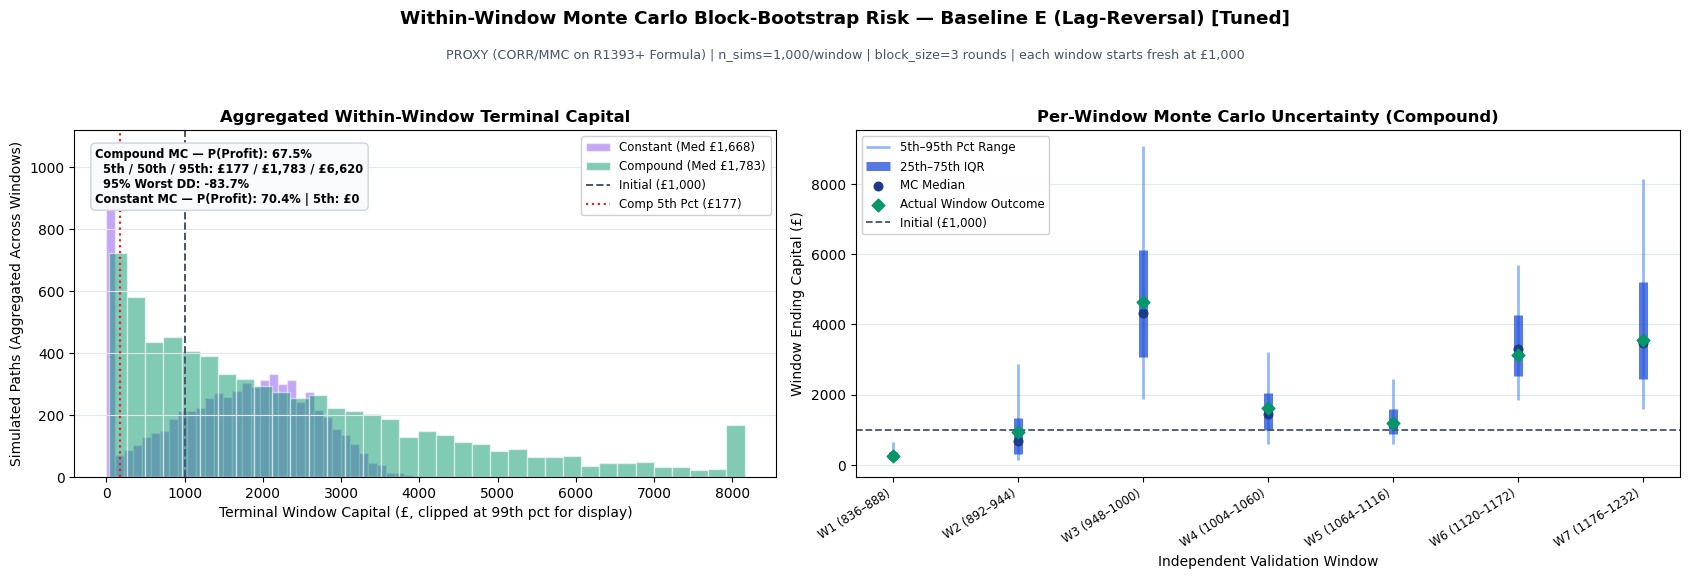

Baseline E (Lag-Reversal) [Tuned] [Within-Window MC] | Compound P(Profit): 67.5% | 5th/50th/95th: £177 / £1,783 / £6,620 | 95% Worst DD: -83.7% | Constant P(Profit): 70.4%


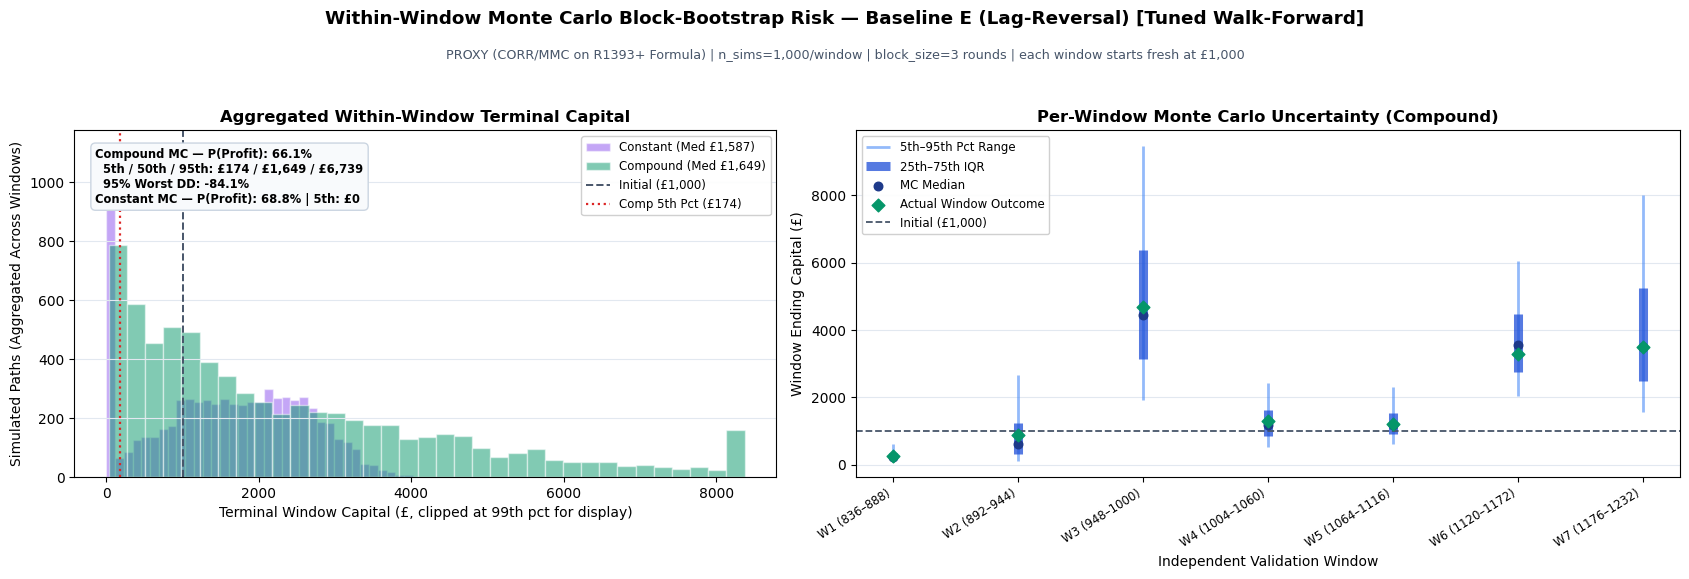

Baseline E (Lag-Reversal) [Tuned Walk-Forward] [Within-Window MC] | Compound P(Profit): 66.1% | 5th/50th/95th: £174 / £1,649 / £6,739 | 95% Worst DD: -84.1% | Constant P(Profit): 68.8%


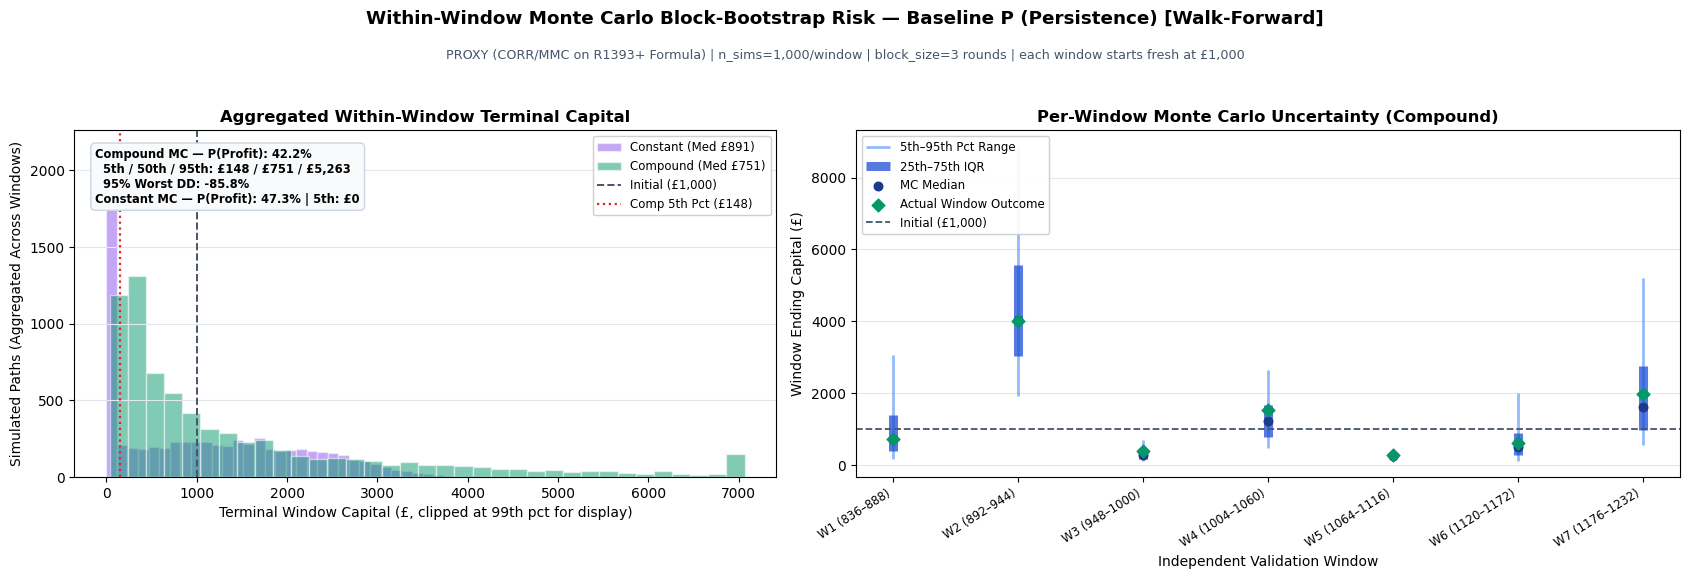

Baseline P (Persistence) [Walk-Forward] [Within-Window MC] | Compound P(Profit): 42.2% | 5th/50th/95th: £148 / £751 / £5,263 | 95% Worst DD: -85.8% | Constant P(Profit): 47.3%


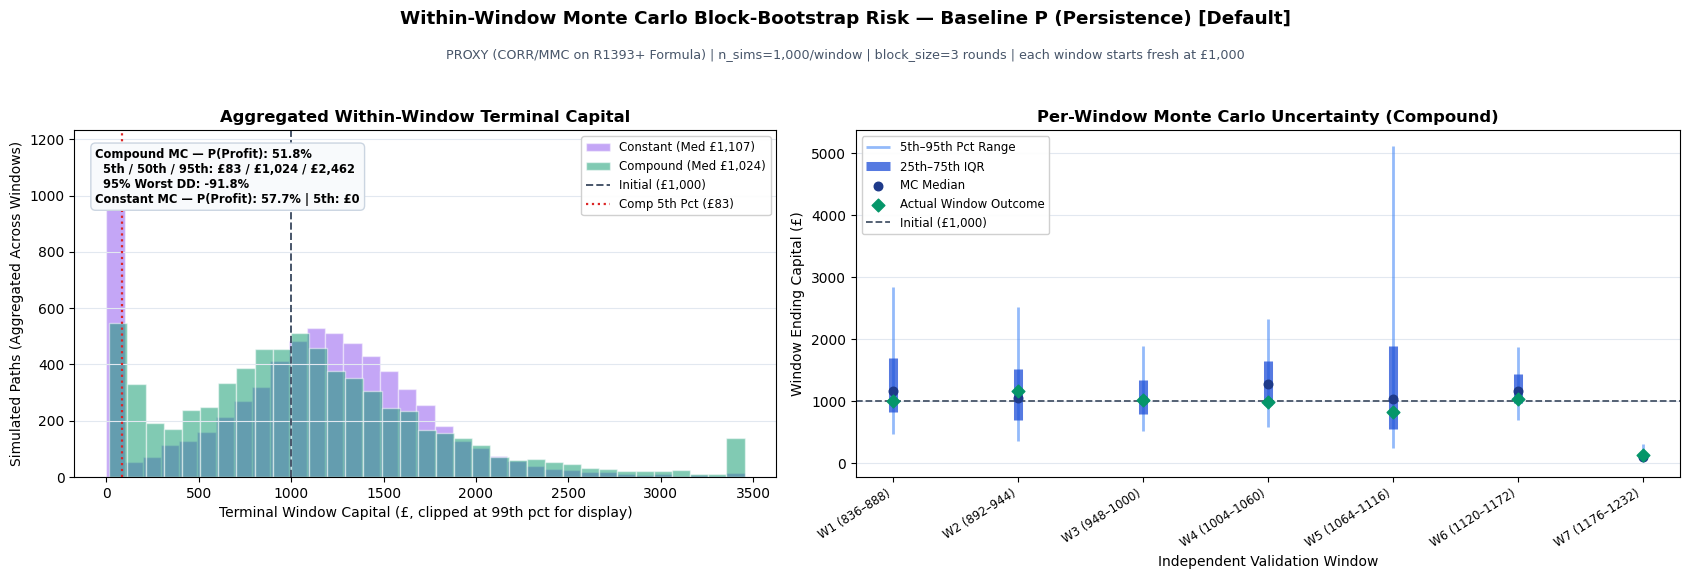

Baseline P (Persistence) [Default] [Within-Window MC] | Compound P(Profit): 51.8% | 5th/50th/95th: £83 / £1,024 / £2,462 | 95% Worst DD: -91.8% | Constant P(Profit): 57.7%


In [18]:
mc_risk_by_variant = {}
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    mc_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_monte_carlo_pnl.png'
        if save_results
        else None
    )
    title_label = f'[BEST] {variant_name}' if is_best_variant else variant_name
    mc_risk_by_variant[variant_name] = plot_stake_pnl_monte_carlo(
        baseline_results[variant_name]['validation_era_corrs'],
        per_era_mmc=variant_era_mmc_by_variant.get(variant_name),
        title=title_label,
        initial_stake=1000.0,
        corr_weight=8.0,
        mmc_weight=32.0,
        payout_factor=1.0,
        clip_min=-0.25,
        clip_max=0.25,
        stride=4,
        window_rounds=13,
        score_basis='corr_mmc_proxy',
        n_sims=1000,
        block_size=3,
        random_state=random_state,
        save_path=mc_save_path,
    )
    v_mc = mc_risk_by_variant[variant_name]
    c_mc = v_mc['constant_mc']
    print(
        f"{title_label} [Within-Window MC] | Compound P(Profit): {v_mc['mc_prob_profit_pct']:.1f}% | "
        f"5th/50th/95th: £{v_mc['mc_p05_final_stake']:,.0f} / £{v_mc['mc_median_final_stake']:,.0f} / £{v_mc['mc_p95_final_stake']:,.0f} | "
        f"95% Worst DD: {v_mc['mc_p95_max_drawdown_pct']:.1f}% | "
        f"Constant P(Profit): {c_mc['mc_prob_profit_pct']:.1f}%"
    )


## Optional Experiment Tracking (Weights & Biases)

In [19]:
if use_wandb:
    if wandb is None:
        print('Skipping W&B logging: wandb is not installed.')
    else:
        wandb_run = wandb.init(
            project=wandb_project,
            name=experiment_name,
            config={
                'data_version': data_version,
                'era_tag': era_tag,
                'model_tag': model_tag,
                'TARGET_COL': TARGET_COL,
                'feature_set': feature_set,
                'era_stride': era_stride,
                'baseline_mode': baseline_mode,
                'search_mode': search_mode,
                'cv_strategy': cv_strategy,
                'n_splits': n_splits,
                'cv_split': cv_split,
                'downsample_mode': downsample_mode,
                'downsample_frac': downsample_frac,
                'target_horizon_eras': target_horizon_eras,
                'embargo_eras': embargo_eras,
                'eval_mode': eval_mode,
                'walk_forward_step_eras': walk_forward_step_eras,
                'walk_forward_window': walk_forward_window,
                'era_weighting': era_weighting,
                'recency_decay': recency_decay,
                'random_state': random_state,
                'n_iter': n_iter,
                'verbose': verbose,
                'n_jobs': n_jobs,
                'error_bin_mode': error_bin_mode,
            },
        )
        log_payload = {
            'comparison_table': wandb.Table(dataframe=comparison_df),
            'search_summary_table': wandb.Table(dataframe=search_summary_df.drop(columns=['best_params'], errors='ignore')),
            'timing/prep_elapsed_s': float(prep_elapsed_s),
            'timing/train_elapsed_s': float(train_elapsed_s),
        }
        for b_name, b_cv_df in cv_results_by_baseline.items():
            b_slug = b_name.lower().replace(' ', '_').replace('(', '').replace(')', '').replace('-', '_')
            log_payload[f'cv_table/{b_slug}'] = wandb.Table(dataframe=b_cv_df.astype(str))
        for row in search_summary_rows:
            b_slug = row['baseline'].lower().replace(' ', '_').replace('(', '').replace(')', '').replace('-', '_')
            log_payload[f'best_cv_corr/{b_slug}'] = float(row['best_cv_corr'])
        wandb.log(log_payload)
        wandb.finish()
        print('Logged experiment tables and metrics to Weights & Biases.')
else:
    print('W&B tracking disabled (use_wandb=False).')

W&B tracking disabled (use_wandb=False).
